# BIL545 · Proje 1 · Vizeye kadarki konular (2.–7. haftalar)
**Veri Madenciliğinde İleri Konular · 2026–2027 Güz** · **Vize notu** · Teslim ve sunum: **8. hafta**

Bu defter projenin şablonudur. Grubunuz defteri kendi Drive'ına kopyalar (**Dosya → Drive'a kopya kaydet**), doldurur ve **iki yere** yükler: GitHub deposundaki `proje1/` klasörüne ve STIX'teki ödev alanına. Bütün yazılı cevaplar bu defterin metin hücrelerindedir; ayrı bir rapor yoktur.

**Kapsam grup tipine göre:** 1–3 kişilik gruplar Bölüm 1–3'ü, 4 kişilik gruplar ek olarak Ek paket 1'i, 5 kişilik gruplar Ek paket 1 ve 2'yi yapar. Grubunuzun yapmadığı ek paket bölümlerini silin. Defterin sonundaki **katkı beyanı puanlanır**; sunumda her üye en az bir alt başlığı anlatır.

**Teslimden önce:** Çalışma zamanını sıfırlayıp **Çalışma Zamanı → Tümünü çalıştır** ile defteri baştan sona hatasız çalıştırın.

**Puanlama:** Başarım puanlanmaz. Her bölüm kurulumun doğruluğu (%30), kararların gerekçesi (%25), dürüst raporlama (%25), yorum (%15) ve teknik düzene (%5) göre puanlanır. Ayrıntılar: *Proje 1 ve Proje 2 Yönergesi*.

## Grup bilgisi

| | Ad Soyad | Öğrenci no |
|---|---|---|
| Tek kişi | **[DOLDURULACAK]** | **[DOLDURULACAK]** |

- **Grup adı:** Bireysel çalışma
- **Grup tipi:** 1 kişi — yalnızca Bölüm 1, 2 ve 3
- **Araştırma sorusu:** Bir e-ticaret oturumunun kaydedilmiş davranışsal özellikleri, satın almayla sonuçlanan oturumları güvenilir biçimde ayırt etmede ne kadar etkilidir?

**Not:** Bu soru oturum verilerindeki sonuçla ilişkileri inceler; oturum tamamlanmadan yapılan canlı tahmin iddiasında bulunmak için özelliklerin hangi aşamada bilindiği ayrıca değerlendirilmelidir.


## Hazırlık

In [ ]:
import sys, numpy as np, pandas as pd, sklearn
SEED = 42
np.random.seed(SEED)
print("Python      ", sys.version.split()[0]); print("numpy       ", np.__version__)
print("pandas      ", pd.__version__);          print("scikit-learn", sklearn.__version__)

Python       3.13.18
numpy        2.4.6
pandas       2.2.3
scikit-learn 1.6.1


### Veriyi yükleme

- **Kaynak:** UCI Machine Learning Repository — [Online Shoppers Purchasing Intention Dataset](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset)
- **Lisans:** CC BY 4.0 (veri seti sayfasında doğrulanacak)
- **İndirme / yükleme adımı:** `ucimlrepo` ile UCI veri kümesi ID 468 otomatik indirilir. Ham veri GitHub'a yüklenmez.
- **Hedef değişken:** `Revenue` (satın alma ile sonuçlanma)
- **Kontrol:** Başarıyla indirildikten sonra boyut, veri türleri, hedef dağılımı ve tekrarlar incelenir.


In [ ]:
# UCI 468 veri kümesini kaynağından otomatik getirir.
# Colab internete bağlı olmalıdır; veri dosyası GitHub'a yüklenmez.
%pip -q install ucimlrepo
from ucimlrepo import fetch_ucirepo

uci_online_shoppers = fetch_ucirepo(id=468)
X = uci_online_shoppers.data.features.copy()
y_source = uci_online_shoppers.data.targets.copy()
y = y_source['Revenue'] if 'Revenue' in y_source.columns else y_source.iloc[:, 0]
y = y.astype(bool)
df = X.copy()
df['Revenue'] = y.to_numpy()

print('Satır x sütun:', df.shape)
print('Özellik sayısı:', X.shape[1])
print('Hedef değişken dağılımı:')
print(df['Revenue'].value_counts(dropna=False))
print('Hedef yüzdesi:')
print(df['Revenue'].value_counts(normalize=True, dropna=False).mul(100).round(2))
display(df.head())


Satır x sütun: (12330, 18)
Özellik sayısı: 17
Hedef değişken dağılımı:
Revenue
False    10422
True      1908
Name: count, dtype: int64
Hedef yüzdesi:
Revenue
False    84.53
True     15.47
Name: proportion, dtype: float64


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


# Bölüm 1 · Veri, ön işleme ve sızıntı *(ağırlık 30)*
**Makale:** Kaufman vd. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM TKDD*, 6(4).

**Okuma notu (3–4 cümle):** …

### 1.1 Veri künyesi

| Soru | Cevap |
|---|---|
| Veri seti | **Online Shoppers Purchasing Intention Dataset**, UCI Machine Learning Repository (ID: 468) |
| Kim, hangi amaçla topladı? | UCI kaynak künyesinde veri setinin yaratıcıları **C. Sakar ve Yomi Kastro** olarak belirtilir. Amaç, web oturumlarının davranışsal bilgileriyle satın alma sonucunun incelenmesi ve tahminidir. |
| Hangi dönemi kapsıyor? | UCI açıklamasına göre **bir yıllık dönem**; oturumlar bu dönemde farklı kullanıcılara aittir. Kesin başlangıç/bitiş tarihleri kaynak sayfasında verilmemiştir; 2018 veri setinin UCI'ye bağış yılıdır, veri toplama dönemi olarak alınmaz. |
| Veri birimi | Bir satır, bir **e-ticaret oturumu**. Veri setinde 12.330 oturum, 17 girdi özelliği ve 1 hedef vardır. |
| Hedef gerçek olgu mu, vekil mi? | `Revenue`, oturumun alışverişle sonuçlanıp sonuçlanmadığının kaydıdır (gözlenen ikili sonuç). Daha sonraki müşteri değeri veya satın alma niyeti gibi kavramların doğrudan ölçümü değildir. |
| Kimler eksik temsil ediliyor olabilir? | Satın alan oturumlar azınlıktadır (%15,47). Ayrıca veri tek kaynaktan geldiğinden farklı mağaza, ülke, cihaz veya demografik kesimlere genellenebilirlik doğrulanmamıştır; kaynakta demografik kapsam ayrıntısı yoktur. |
| Lisans | **CC BY 4.0** — kaynak göstererek kullanım ve uyarlama mümkündür. |
| Kaynak / DOI | https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset · https://doi.org/10.24432/C5F88Q |

**Bilimsel not:** Oturum boyunca değişen özelliklerin (ör. `ProductRelated_Duration`, `ExitRates`, `PageValues`) hangi anda bilindiği, olası bir erken tahmin senaryosunda ayrıca incelenmelidir. Bu sütunlar sırf hedefle güçlü ilişkili oldukları için otomatik olarak "sızıntı" diye etiketlenemez.


In [ ]:
# UCI veri setinin resmî değişken künyesini görüntüle.
# Veri künyesi kaynak metniyle birlikte değerlendirilmelidir.
print("Kaynak:", "https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset")
print("Veri birimi: oturum")
print("Girdi özelliği sayısı:", X.shape[1])
print("Gözlem sayısı:", len(df))
print("Hedef değişken:", y.name)
print("Hedef sınıflarının oranı (%):")
display(df["Revenue"].value_counts(normalize=True).mul(100).round(2).rename("Yüzde (%)").to_frame())
print("UCI değişken açıklamaları:")
display(uci_online_shoppers.variables)


Kaynak: https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset
Veri birimi: oturum
Girdi özelliği sayısı: 17
Gözlem sayısı: 12330
Hedef değişken: Revenue
Hedef sınıflarının oranı (%):


,Yüzde (%)
Revenue,
False,84.53
True,15.47


UCI değişken açıklamaları:


,name,role,type,demographic,description,units,missing_values
0,Administrative,Feature,Integer,None,None,None,no
1,Administrative_Duration,Feature,Integer,None,None,None,no
2,Informational,Feature,Integer,None,None,None,no
3,Informational_Duration,Feature,Integer,None,None,None,no
4,ProductRelated,Feature,Integer,None,None,None,no
5,ProductRelated_Duration,Feature,Continuous,None,None,None,no
6,BounceRates,Feature,Continuous,None,None,None,no
7,ExitRates,Feature,Continuous,None,None,None,no
8,PageValues,Feature,Integer,None,None,None,no
9,SpecialDay,Feature,Integer,None,None,None,no


**Yorum — 1.1 Veri künyesi**

Veri seti 12.330 e-ticaret oturumundan oluşmaktadır. 10.422 oturum (%84,53) satın almayla sonuçlanmazken 1.908 oturum (%15,47) satın almayla sonuçlanmıştır. Bu nedenle veri kümesi sınıf dengesizliği içermektedir. Çoğunluk sınıfını sürekli tahmin eden bir yaklaşımın doğruluğu %84,53 olacağından, sonraki sınıflandırma modelleri yalnızca accuracy ile değerlendirilmemelidir.

UCI kaynağına göre kayıtlar bir yıllık dönemdendir, ancak kesin tarih aralığı belirtilmemiştir. `Revenue` alışveriş sonucunu temsil eder; kullanıcıların öznel satın alma niyetini doğrudan ölçmez. Kullanıcı veya mağaza çeşitliliğine ilişkin yeterli demografik ayrıntı bulunmadığından sonuçlar her e-ticaret ortamına doğrudan genellenemez.


### 1.2 Keşifsel veri analizi

Bu hücrede **verinin boyutunu, saklama ve ölçüm türlerini, sınıf dağılımını, yinelenen satırları** ve her girdi özelliği için **veri tipi, eksik oranı, benzersiz değer sayısı ve sıfır oranını** inceleyin.

**Önemli ayrım:** `OperatingSystems`, `Browser`, `Region` ve `TrafficType` tam sayı olarak saklansa da sayısal büyüklük değil **kategorik kod** olarak yorumlanır. `Month`, `VisitorType` ve `Weekend` de kategoriktir. Sıfır oranını yorumlamak sayısal ölçümler için anlamlıdır.

Şüpheli/görev zamanlamasına bağlı dikkat gerektiren değişkenler: `PageValues`, `ExitRates`, `BounceRates` ve oturum boyunca biriken süreler. Bunlar otomatik olarak çıkarılmayacak; önce özelliklerin hangi anda mevcut olduğu araştırılacaktır.


Boyut (oturum x tüm sütunlar): (12330, 18)
Girdi özellikleri: 17
Tamamen aynı satırlar (hedef dahil): 125
Aynı girdi özelliklerine sahip satırlar (hedef hariç): 125
Gerçek NaN sayısı (tüm tablo): 0
Bellek kullanımı (MB): 2.718


,Öznitelik,Saklama tipi,Ölçek türü,Eksik (%),Farklı değer,Sıfır (%)
0,Administrative,int64,Sayısal / sayım,0.0,27,46.78
1,Administrative_Duration,float64,Sayısal / sürekli veya oran,0.0,3335,47.88
2,Informational,int64,Sayısal / sayım,0.0,17,78.66
3,Informational_Duration,float64,Sayısal / sürekli veya oran,0.0,1258,80.49
4,ProductRelated,int64,Sayısal / sayım,0.0,311,0.31
5,ProductRelated_Duration,float64,Sayısal / sürekli veya oran,0.0,9551,6.12
6,BounceRates,float64,Sayısal / sürekli veya oran,0.0,1872,44.75
7,ExitRates,float64,Sayısal / sürekli veya oran,0.0,4777,0.62
8,PageValues,float64,Sayısal / sürekli veya oran,0.0,2704,77.86
9,SpecialDay,float64,Sayısal / sürekli veya oran,0.0,6,89.85


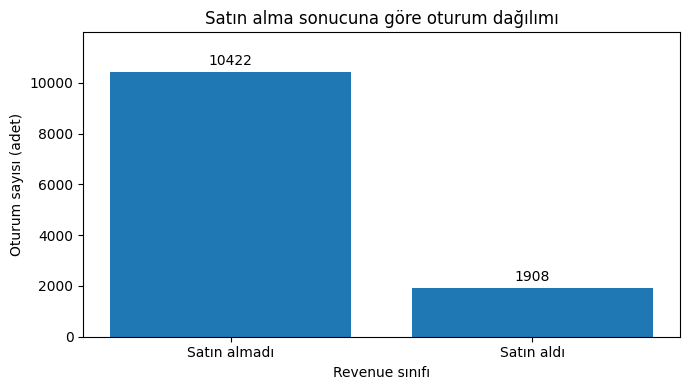

Grafik yorumu: Satın alan sınıfı belirgin şekilde daha azdır;
yalnızca doğruluk ölçütüne bakmak yanıltıcı olabilir.

Month (kategori sayımları):


,Oturum sayısı
Month,
May,3364
Nov,2998
Mar,1907
Dec,1727
Oct,549
Sep,448
Aug,433
Jul,432
June,288



VisitorType (kategori sayımları):


,Oturum sayısı
VisitorType,
Returning_Visitor,10551
New_Visitor,1694
Other,85



Weekend (kategori sayımları):


,Oturum sayısı
Weekend,
False,9462
True,2868



Zamanlama / olası sızıntı için ayrıca denetlenecek özellikler:
['PageValues', 'ExitRates', 'BounceRates', 'ProductRelated_Duration']
Not: Bu liste sızıntının kanıtı değil, denetim hipotezidir.

=== 1.2 KISA KONTROL ÖZETİ ===
Tam yinelenen satırlar: 125
Girdi özellikleri aynı satırlar: 125
Toplam eksik hücre: 0
Eksik değerli özellikler: []
En fazla farklı değer içeren 5 özellik:


,Öznitelik,Farklı değer
5,ProductRelated_Duration,9551
7,ExitRates,4777
1,Administrative_Duration,3335
8,PageValues,2704
6,BounceRates,1872


Sıfır oranı en yüksek 5 sayısal özellik:


,Öznitelik,Sıfır (%)
9,SpecialDay,89.85
3,Informational_Duration,80.49
2,Informational,78.66
8,PageValues,77.86
1,Administrative_Duration,47.88


In [ ]:
import matplotlib.pyplot as plt

# 1.2.1: Temel veri denetimi
print("Boyut (oturum x tüm sütunlar):", df.shape)
print("Girdi özellikleri:", X.shape[1])
print("Tamamen aynı satırlar (hedef dahil):", int(df.duplicated().sum()))
print("Aynı girdi özelliklerine sahip satırlar (hedef hariç):", int(X.duplicated().sum()))
print("Gerçek NaN sayısı (tüm tablo):", int(df.isna().sum().sum()))
print("Bellek kullanımı (MB):", round(df.memory_usage(deep=True).sum() / (1024 ** 2), 3))

# 1.2.2: Saklama tipi ile analizdeki ölçüm türünü ayır.
nominal_columns = {
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend"
}
count_columns = {"Administrative", "Informational", "ProductRelated"}

rows = []
for col in X.columns:
    ser = X[col]
    is_category = col in nominal_columns
    if is_category:
        scale = "Kategorik / nominal"
    elif col in count_columns:
        scale = "Sayısal / sayım"
    else:
        scale = "Sayısal / sürekli veya oran"
    has_meaningful_zero = (not is_category) and pd.api.types.is_numeric_dtype(ser)
    zero_pct = round(float(ser.eq(0).mean() * 100), 2) if has_meaningful_zero else np.nan
    rows.append({
        "Öznitelik": col,
        "Saklama tipi": str(ser.dtype),
        "Ölçek türü": scale,
        "Eksik (%)": round(float(ser.isna().mean() * 100), 2),
        "Farklı değer": int(ser.nunique(dropna=True)),
        "Sıfır (%)": zero_pct,
    })
profile_table = pd.DataFrame(rows)
display(profile_table)

# 1.2.3: Hedef değişken dağılımı
counts = df["Revenue"].value_counts().reindex([False, True], fill_value=0)
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(["Satın almadı", "Satın aldı"], counts.to_numpy())
ax.bar_label(bars, padding=3)
ax.set_xlabel("Revenue sınıfı")
ax.set_ylabel("Oturum sayısı (adet)")
ax.set_title("Satın alma sonucuna göre oturum dağılımı")
ax.set_ylim(0, max(counts) * 1.15)
fig.tight_layout()
plt.show()
print("Grafik yorumu: Satın alan sınıfı belirgin şekilde daha azdır;")
print("yalnızca doğruluk ölçütüne bakmak yanıltıcı olabilir.")

# 1.2.4: Kategorik sütunları ve riskli olabilecek özellikleri görünür kıl.
for col in ["Month", "VisitorType", "Weekend"]:
    print(f"\n{col} (kategori sayımları):")
    display(X[col].value_counts(dropna=False).rename("Oturum sayısı").to_frame())

print("\nZamanlama / olası sızıntı için ayrıca denetlenecek özellikler:")
print(["PageValues", "ExitRates", "BounceRates", "ProductRelated_Duration"])
print("Not: Bu liste sızıntının kanıtı değil, denetim hipotezidir.")

# 1.2.5: Ekran görüntüsü yerine kısa ve doğrulanabilir özet
print("\n=== 1.2 KISA KONTROL ÖZETİ ===")
print("Tam yinelenen satırlar:", int(df.duplicated().sum()))
print("Girdi özellikleri aynı satırlar:", int(X.duplicated().sum()))
print("Toplam eksik hücre:", int(df.isna().sum().sum()))
print("Eksik değerli özellikler:", profile_table.loc[profile_table["Eksik (%)"] > 0, "Öznitelik"].tolist())
print("En fazla farklı değer içeren 5 özellik:")
display(profile_table.sort_values("Farklı değer", ascending=False)[["Öznitelik", "Farklı değer"]].head(5))
print("Sıfır oranı en yüksek 5 sayısal özellik:")
display(profile_table.dropna(subset=["Sıfır (%)"]).sort_values("Sıfır (%)", ascending=False)[["Öznitelik", "Sıfır (%)"]].head(5))


**Yorum — 1.2 Keşifsel analiz (Colab çıktılarıyla doğrulanmıştır)**

Veri setinde **12.330 oturum, 17 girdi özelliği ve bir ikili hedef** bulunmaktadır. Satın alma ile sonuçlanan oturumlar 1.908 (%15,47), diğerleri 10.422 (%84,53) adettir. Bu sınıf dengesizliği nedeniyle yalnızca accuracy yerine balanced accuracy, F1 veya average precision gibi ölçütlerin de raporlanması gerekir.

- **Yinelenen kayıtlar:** Tamamen aynı **125 satır** vardır; hedef hariç girdileri aynı olan satırların sayısı da **125**'tir. Bu yaklaşık **%1,01** oranındadır. Yinelenen satırların gerçek tekrarlayan oturumları mı, yoksa kayıt tekrarlarını mı temsil ettiği mevcut bilgilerden anlaşılamaz; bu nedenle veri keşfi sırasında sessizce silinmemiştir. Sınıflandırma aşamasında bu satırların çapraz doğrulamayı iyimser kılmaması için grup bazlı ayırma veya yinelenen kayıtları çıkarma duyarlılık kontrolü yapılacaktır.
- **Eksik değerler:** Gerçek veri tablosundaki toplam eksik hücre **0**'dır; hiçbir girdi özelliğinde gözlenen NaN bulunmamaktadır. Sıfır değerleri eksiklik sayılmamıştır.
- **Yüksek farklı değer sayısı:** `ProductRelated_Duration` 9.551 farklı değer içerir; bu sürekli bir ölçüm olduğundan yüksek benzersiz değer sayısı tek başına kategorik kodlama gerektirmez. Kategorik değişkenlerden `TrafficType` (**20 kategori**) ve `Browser` (**13 kategori**) farklı kodlama stratejileri için adaydır.
- **Sıfırların yoğunluğu:** Sayısal ölçümlerde `SpecialDay` **%89,85**, `Informational_Duration` **%80,49**, `Informational` **%78,66**, `PageValues` **%77,86** sıfır değer içerir. Bu, otomatik olarak eksik veri anlamına gelmez.
- **Oturum profili:** En fazla oturum Mayıs (**3.364**) ve Kasım (**2.998**) aylarındadır. `Returning_Visitor` sınıfında **10.551** kayıt vardır. Oturumların **9.462**'si hafta içi, **2.868**'i hafta sonudur. Oturum sayısı tek başına satın alma oranına dair yorum yapmaya yetmez.
- **Zamanlamaya bağlı sızıntı riski:** `PageValues`, `ExitRates`, `BounceRates` ve oturum boyunca biriken süreler erken tahmin amacıyla kullanıldığında özelliklerin hangi anda bilindiği özellikle incelenmelidir. Bu sütunlar kendiliğinden sızıntı kanıtı değildir.

**Sınırlılık:** Tam tekrarlanan kayıtların kaynağı ve hangi özelliklerin oturumun hangi anında oluştuğu doğrudan bu tablodan belirlenememektedir; kararlar sonraki deneylerle açıkça gerekçelendirilecektir.


### 1.3 Eksiklik analizi — gerçek eksiklik yoksa kontrollü deney

Yönergede eksik kodlarının NaN'a çevrilmesi, eksiklik deseninin incelenmesi, iki sütunda MCAR/MAR/MNAR mekanizmalarının tartışılması ve `SimpleImputer(add_indicator=True)` etkisinin ölçülmesi istenir.

**Veriye özgü durum:** UCI 468'in incelenen sürümünde gerçek eksik hücre sayısı **0**'dır. Bu durumda gerçek veriden "en çok eksiği olan iki sütun" seçmek veya mekanizma türünü istatistiksel olarak tahmin etmek mümkün değildir. Sıfırlar gerçek ölçüm kabul edilir, otomatik olarak NaN'a çevrilmez.

Bu nedenle **orijinal `X` ve `df` değiştirilmeden**, yalnızca bu alt bölüm için **ayrı bir sentetik eksiklik deneyi** yapılacaktır:

1. `Administrative_Duration` özelliğinde her kayıt için bağımsız %15 olasılıkla **MCAR** (tamamen rastgele eksiklik) oluşturulur.
2. `Informational_Duration` özelliğinde eksiklik olasılığı, gözlenen `ProductRelated` değerine göre belirlendiğinden **MAR** (gözlenen bir başka özellikle ilişkili eksiklik) örneklenir.
3. **MNAR**, eksiklik olasılığının eksik bırakılan değerin kendisine bağlı olmasıdır. Gerçek eksiklik olmadığı için bu veri setinde MNAR olduğunu iddia edemeyiz; yalnızca teorik olarak tartışırız.
4. Eksikliği gösteren ek göstergeler açık/kapalı iken **aynı 5×2 tekrarlı katmanlı çapraz doğrulama bölmeleri** üzerinde LogisticRegression sonuçları karşılaştırılır. İmputasyon, kodlama ve ölçekleme her eğitim katında yeniden öğrenilir (`Pipeline`).

> **Önemli:** Sentetik eksiklikler **gerçek veri kümesinin bir özelliği gibi raporlanmaz**. Bu bir öğretici yöntem karşılaştırmasıdır; ana modelleme çalışmalarında özgün veri kullanılır. Gerçek MCAR/MAR/MNAR mekanizması hakkında kanıt değildir. Öğretim üyesinin eksik verisiz veri kümeleri için beklediği yaklaşım farklıysa bu deneyin kabulünü teyit etmek gerekir.


=== A: GERÇEK VERİ DENETİMİ ===
Gerçek NaN hücre sayısı: 0
Kontrol edilen özel eksik belirteçlerin toplam sayısı: 0
Eksik belirteç bulunan sütunlar: {}
NOT: Sayısal sıfırlar otomatik olarak eksik kabul EDİLMEDİ.

=== B: YALNIZCA DENEY İÇİN SENTETİK EKSİKLİK ===


,Sentetik eksiklik (%)
Administrative_Duration,15.0
Informational_Duration,21.8


MCAR gerçekleşen kayıt sayısı: 1849
MAR gerçekleşen kayıt sayısı: 2688
Orijinal X tablosunda eksiklik yine: 0


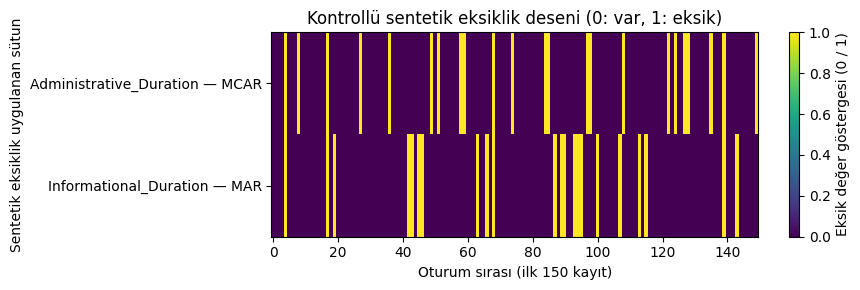

Grafik yorumu: Desen yalnızca yapay deneyde eklenen eksikleri gösterir.

=== C: EKSİKLİK GÖSTERGESİ KARŞILAŞTIRMASI ===


,add_indicator,balanced_accuracy ortalama,balanced_accuracy std,average_precision ortalama,average_precision std
0,False,0.8124,0.0123,0.6500,0.0248
1,True,0.8118,0.0121,0.6499,0.0250


Her iki model için 5 kat × 2 tekrar = 10 doğrulama skoru karşılaştırıldı.
Ölçütler: dengeli doğruluk ve average precision (PR-AUC özeti).
NOT: Bu deney yapay eksiklik üzerindedir; gerçek veri seti eksiksizdir.


In [ ]:
# BÖLÜM 1.3 — GERÇEK EKSİKLİK DENETİMİ VE AYRI SENTETİK DENEY
# Orijinal X, y, df üzerinde değişiklik YAPILMAZ.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline

# (A) Gerçek verinin eksiklik ve eksik-kodu denetimi
print("=== A: GERÇEK VERİ DENETİMİ ===")
print("Gerçek NaN hücre sayısı:", int(X.isna().sum().sum()))
missing_tokens = {"?", "NA", "N/A", "NULL", "null", "", " "}
token_counts = {col: int(X[col].astype(str).str.strip().isin(missing_tokens).sum())
                for col in X.columns}
print("Kontrol edilen özel eksik belirteçlerin toplam sayısı:", sum(token_counts.values()))
print("Eksik belirteç bulunan sütunlar:",
      {k: v for k, v in token_counts.items() if v > 0})
print("NOT: Sayısal sıfırlar otomatik olarak eksik kabul EDİLMEDİ.")

# (B) Kontrollü ve şeffaf sentetik eksiklik oluşturma
print("\n=== B: YALNIZCA DENEY İÇİN SENTETİK EKSİKLİK ===")
rng = np.random.default_rng(SEED)
X_missing_sim = X.copy(deep=True)

# MCAR: Administrative_Duration için tüm satırlarda sabit eksiklik olasılığı
mcar_mask = rng.random(len(X_missing_sim)) < 0.15
X_missing_sim.loc[mcar_mask, "Administrative_Duration"] = np.nan

# MAR: Informational_Duration eksikliği, gözlenen ProductRelated'e bağlı
mar_probability = np.where(X["ProductRelated"].to_numpy() >= 10, 0.30, 0.05)
mar_mask = rng.random(len(X_missing_sim)) < mar_probability
X_missing_sim.loc[mar_mask, "Informational_Duration"] = np.nan

sim_missing_percent = (X_missing_sim.isna().mean() * 100).round(2)
display(sim_missing_percent[sim_missing_percent > 0]
        .rename("Sentetik eksiklik (%)").to_frame())
print("MCAR gerçekleşen kayıt sayısı:", int(mcar_mask.sum()))
print("MAR gerçekleşen kayıt sayısı:", int(mar_mask.sum()))
print("Orijinal X tablosunda eksiklik yine:", int(X.isna().sum().sum()))

# Eksiklik desenini ilk 150 oturum için görselleştirme
mask_view = X_missing_sim[
    ["Administrative_Duration", "Informational_Duration"]
].isna().iloc[:150].T
fig, ax = plt.subplots(figsize=(9, 3))
im = ax.imshow(mask_view.to_numpy(), aspect="auto", interpolation="nearest",
               vmin=0, vmax=1)
ax.set_yticks([0, 1])
ax.set_yticklabels(["Administrative_Duration — MCAR",
                    "Informational_Duration — MAR"])
ax.set_xlabel("Oturum sırası (ilk 150 kayıt)")
ax.set_ylabel("Sentetik eksiklik uygulanan sütun")
ax.set_title("Kontrollü sentetik eksiklik deseni (0: var, 1: eksik)")
fig.colorbar(im, ax=ax, label="Eksik değer göstergesi (0 / 1)")
fig.tight_layout()
plt.show()
print("Grafik yorumu: Desen yalnızca yapay deneyde eklenen eksikleri gösterir.")

# (C) add_indicator=False / True karşılaştırması
print("\n=== C: EKSİKLİK GÖSTERGESİ KARŞILAŞTIRMASI ===")
categorical_columns = [
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend"
]
numeric_columns = [c for c in X.columns if c not in categorical_columns]

def make_missingness_pipeline(add_indicator):
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median",
                                  add_indicator=add_indicator)),
        ("scaler", StandardScaler())
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])
    preprocessing = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_columns),
        ("categorical", categorical_pipeline, categorical_columns)
    ])
    return Pipeline([
        ("preprocessing", preprocessing),
        ("classifier", LogisticRegression(
            class_weight="balanced", max_iter=2000, random_state=SEED
        ))
    ])

cv_missingness = RepeatedStratifiedKFold(
    n_splits=5, n_repeats=2, random_state=SEED
)
metric_names = {
    "balanced_accuracy": "balanced_accuracy",
    "average_precision": "average_precision"
}
cv_rows = []
for indicator_setting in [False, True]:
    model = make_missingness_pipeline(indicator_setting)
    scores = cross_validate(
        model, X_missing_sim, y, cv=cv_missingness,
        scoring=metric_names, n_jobs=1, error_score="raise"
    )
    row = {"add_indicator": indicator_setting}
    for metric in metric_names:
        vals = scores[f"test_{metric}"]
        row[f"{metric} ortalama"] = round(float(np.mean(vals)), 4)
        row[f"{metric} std"] = round(float(np.std(vals, ddof=1)), 4)
    cv_rows.append(row)

missing_indicator_results = pd.DataFrame(cv_rows)
display(missing_indicator_results)
print("Her iki model için 5 kat × 2 tekrar = 10 doğrulama skoru karşılaştırıldı.")
print("Ölçütler: dengeli doğruluk ve average precision (PR-AUC özeti).")
print("NOT: Bu deney yapay eksiklik üzerindedir; gerçek veri seti eksiksizdir.")


**Yorum — 1.3 Eksiklik analizi (Colab'da doğrulanmıştır)**

**Gerçek veri:** 17 girdi özelliğinin tamamında gerçek eksik hücre sayısı **0**'dır. Özel eksik belirteçlerin taramasında da **0** bulundu. Sıfır değerleri gerçek ölçümler olarak korundu.

**Yapay eksiklik deneyi:** Orijinal veri değiştirilmedi. Sadece deney kopyasında `Administrative_Duration` için MCAR yaklaşımıyla **1.849 gözlem (%15,0)**, `Informational_Duration` için `ProductRelated` değişkeniyle bağlantılı MAR yaklaşımıyla **2.688 gözlem (%21,8)** eksik bırakıldı. Görsel, yalnızca yapay eksiklik desenini göstermektedir. Gerçek veride MCAR, MAR veya MNAR mekanizması bulunduğu ileri sürülemez.

**Modellerin karşılaştırılması (5 kat × 2 tekrar):**

| Yöntem | Balanced accuracy (ortalama ± ss) | Average precision (ortalama ± ss) |
|---|---|---|
| `add_indicator=False` | **0,8124 ± 0,0123** | **0,6500 ± 0,0248** |
| `add_indicator=True` | **0,8118 ± 0,0121** | **0,6499 ± 0,0250** |

Eksiklik göstergesiyle dengeli doğrulukta **0,0006**, average precision'da **0,0001** düşüş gözlendi. Bu küçük farklar yapay deneyimizde ek göstergenin pratik faydasına kanıt sunmamaktadır. Ancak istatistiksel anlamlılık testi yapılmadığından anlamlılık hakkında kesin hüküm kurulamaz.

**Yöntem:** Eksiklik maskesi hedef değişkenden bağımsız olarak üretildi. İmputasyon, kodlama ve ölçekleme modellerin `Pipeline` içinde ve yalnızca eğitim katlarından öğrenildi. Sonuçlar ana veri setinde gerçek eksiklik bulunduğuna veya ana sınıflandırma modelinin başarısına kanıt olarak kullanılmaz. MNAR, eksikliğin gözlenmeyen değere bağlı olduğu mekanizma olarak kavramsal düzeyde açıklanmıştır.


### 1.4 Kategorik kodlama — One-hot, nadir kategori birleştirme ve hedef kodlama

`TrafficType`, **20 kategorisi** olan, sayısal saklanan fakat nominal bir değişkendir. Kıyaslama:

1. One-hot kodlama: trafik türü başına gösterge sütunu.
2. Nadir kategori birleştirme: eğitim katında frekansı %1'den az kategorileri tek nadir kategoride ele alan one-hot kodlama.
3. Kat dışı hedef kodlama: `TargetEncoder` ile eğitim verisi içinde çapraz kodlama ve dış değerlendirme katlarını hiç kullanmama.
4. **Bilerek yanlış** hedef kodlama: tüm veride hedef ortalaması hesaplayıp dış çapraz doğrulamaya girme. Bu, değerlendirme etiketlerini ön işlemeye sızdırdığı için geçersiz deneydir.

Aynı lojistik regresyon, aynı 5 kat × 2 tekrar ve `balanced_accuracy` ile `average_precision` ölçütleri kullanılır. Doğru yöntemlerin bütün dönüşümleri `Pipeline` içinde gerçekleştirilir. Yanlış yöntemin skoru model seçiminde kullanılmayacak, veri sızıntısının neden hatalı olduğu anlatılacaktır.


=== 1.4 TRAFİK TÜRÜ KATEGORİLERİ ===
TrafficType farklı kategori sayısı: 20


,Oturum sayısı
TrafficType,
2,3913
1,2451
3,2052
4,1069
13,738
10,450
6,444
8,343
5,260


Oranı %1'den düşük kategoriler: [9, 7, 15, 19, 14, 18, 16, 12, 17]

=== DOĞRU HATLAR ===

=== BİLEREK HATALI HAT — sadece gösterim ===


,Kodlama,balanced_accuracy ort,balanced_accuracy std,average_precision ort,average_precision std
0,One-hot,0.8126,0.0122,0.6499,0.0245
1,One-hot + nadir (%1),0.8135,0.0127,0.6502,0.0247
2,Kat dışı hedef kodlama,0.8138,0.0111,0.6515,0.0246
3,YANLIŞ: global hedef kodlama,0.8138,0.0113,0.6518,0.0245


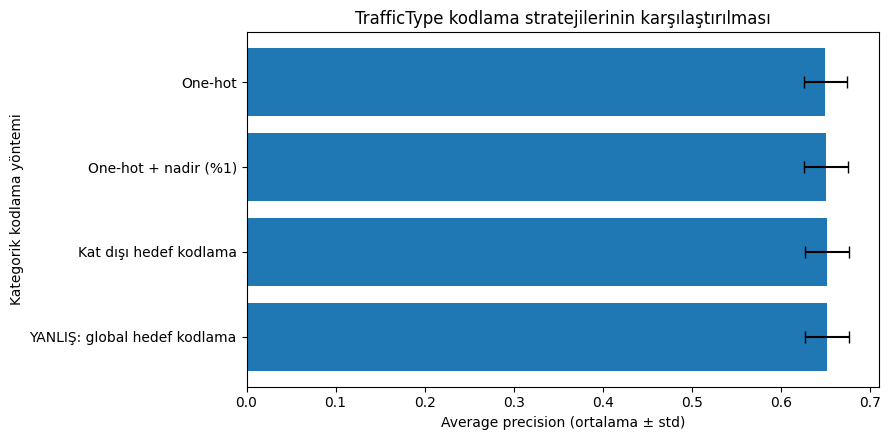

Grafik yorumu: Hata çubukları çapraz doğrulama skorlarının standart sapmasıdır.
UYARI: 'YANLIŞ: global hedef kodlama' geçersizdir; model seçimine katılmaz.


In [ ]:
# BÖLÜM 1.4 — KATEGORİK KODLAMA VE KONTROLLÜ SIZINTI GÖSTERİMİ
# X, y ve df değiştirilmez.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline

print("=== 1.4 TRAFİK TÜRÜ KATEGORİLERİ ===")
print("TrafficType farklı kategori sayısı:", X["TrafficType"].nunique())
display(X["TrafficType"].value_counts().rename("Oturum sayısı").to_frame())
rare_levels = X["TrafficType"].value_counts(normalize=True)
print("Oranı %1'den düşük kategoriler:", rare_levels[rare_levels < .01].index.tolist())

categorical_cols = [
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend"
]
other_categorical_cols = [c for c in categorical_cols if c != "TrafficType"]
numeric_cols = [c for c in X.columns if c not in categorical_cols]

def make_encoder_model(traffic_encoder=None, leaky=False):
    numeric_input_cols = numeric_cols + (["TrafficType_TE_global"] if leaky else [])
    transformers = [
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_input_cols),
        ("other_categorical", OneHotEncoder(handle_unknown="ignore"), other_categorical_cols)
    ]
    if not leaky:
        transformers.append(("traffic", traffic_encoder, ["TrafficType"]))
    prep = ColumnTransformer(transformers)
    return Pipeline([
        ("prep", prep),
        ("model", LogisticRegression(
            class_weight="balanced", random_state=SEED, max_iter=2000
        ))
    ])

cv_encoding = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)
metrics = {"balanced_accuracy": "balanced_accuracy",
           "average_precision": "average_precision"}
rows = []

def evaluate_encoding(name, model, features):
    scores = cross_validate(
        model, features, y, cv=cv_encoding, scoring=metrics,
        n_jobs=1, error_score="raise"
    )
    result = {"Kodlama": name}
    for key in metrics:
        vals = scores["test_" + key]
        result[key + " ort"] = float(vals.mean())
        result[key + " std"] = float(vals.std(ddof=1))
    rows.append(result)

print("\n=== DOĞRU HATLAR ===")
evaluate_encoding("One-hot",
                  make_encoder_model(OneHotEncoder(handle_unknown="ignore")), X)
evaluate_encoding("One-hot + nadir (%1)",
                  make_encoder_model(OneHotEncoder(
                      handle_unknown="infrequent_if_exist", min_frequency=0.01
                  )), X)
evaluate_encoding("Kat dışı hedef kodlama",
                  make_encoder_model(TargetEncoder(
                      target_type="binary", smooth="auto", cv=5,
                      shuffle=True, random_state=SEED
                  )), X)

# YANLIŞ: Tüm veriyle hedef kodlaması dış CV'den önce öğreniliyor.
# Bu, doğrulama etiketlerini dönüşüme sızdıran geçersiz düzenektir.
print("\n=== BİLEREK HATALI HAT — sadece gösterim ===")
global_target_encoder = TargetEncoder(
    target_type="binary", smooth="auto", cv=5,
    shuffle=True, random_state=SEED
)
global_encoded_traffic = global_target_encoder.fit(
    X[["TrafficType"]], y
).transform(X[["TrafficType"]])[:, 0]
X_leaky = X.drop(columns="TrafficType").copy()
X_leaky["TrafficType_TE_global"] = global_encoded_traffic
evaluate_encoding("YANLIŞ: global hedef kodlama", make_encoder_model(leaky=True), X_leaky)

encoding_results = pd.DataFrame(rows)
for col in encoding_results.columns:
    if col != "Kodlama":
        encoding_results[col] = encoding_results[col].round(4)
display(encoding_results)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(encoding_results["Kodlama"], encoding_results["average_precision ort"],
        xerr=encoding_results["average_precision std"], capsize=4)
ax.invert_yaxis()
ax.set_xlabel("Average precision (ortalama ± std)")
ax.set_ylabel("Kategorik kodlama yöntemi")
ax.set_title("TrafficType kodlama stratejilerinin karşılaştırılması")
fig.tight_layout()
plt.show()
print("Grafik yorumu: Hata çubukları çapraz doğrulama skorlarının standart sapmasıdır.")
print("UYARI: 'YANLIŞ: global hedef kodlama' geçersizdir; model seçimine katılmaz.")


**Yorum — 1.4 Kategorik kodlama (Colab'da çalıştırılarak doğrulanmıştır)**

`TrafficType` **20 farklı nominal kategoriden** oluşur; sayısal olarak saklanan kodlar büyüklük sırası ifade etmez. Trafik türlerinin **9 kategorisinde frekans %1'in altındadır** (9, 7, 15, 19, 14, 18, 16, 12, 17). Nadir kategoriler için farklı kodlama seçenekleri aynı deney hattında incelenmiştir.

**Aynı 5 kat × 2 tekrarlı katmanlı çapraz doğrulama ile model sonuçları:**

| Kodlama yöntemi | Balanced accuracy (ortalama ± ss) | Average precision (ortalama ± ss) | Geçerli mi? |
|---|---:|---:|---|
| One-hot | 0,8126 ± 0,0122 | 0,6499 ± 0,0245 | Evet |
| One-hot + nadir kategori (%1) | 0,8135 ± 0,0127 | 0,6502 ± 0,0247 | Evet |
| Kat dışı hedef kodlama | **0,8138 ± 0,0111** | **0,6515 ± 0,0246** | Evet |
| **YANLIŞ:** Global hedef kodlama | 0,8138 ± 0,0113 | 0,6518 ± 0,0245 | **Hayır** |

Üç geçerli yöntem arasında kat dışı hedef kodlama en yüksek ortalama skorları vermiştir; ancak **one-hot'a göre balanced accuracy farkı yalnızca +0,0012, average precision farkı +0,0016** düzeyindedir. Bu küçük farklardan tek başına istatistiksel üstünlük sonucu çıkarılamaz. Nadir kategorileri birleştirmek de bu deneyde yalnızca küçük bir değişim sağlamıştır.

**Bilerek yanlış kurulumun sınırı:** Global hedef kodlama `TrafficType` sınıf ortalamalarını **tüm hedef etiketlerinden** öğrenir; dış doğrulama katlarının hedefleri de bu ortalamalara karışır. Bu nedenle sonuç değerlendirme açısından **geçersizdir**. Yanlış global kodlama ile doğru kat dışı kodlamanın average precision ortalamaları arasındaki fark **+0,0003** olsa da bunun gerçek iyileşme olarak sunulması uygun değildir. Benzer skorların elde edilmesi veri sızıntısını meşru kılmaz.

**Karar:** İlk değerlendirmede kat dışı hedef kodlama küçük bir ortalama avantaja sahiptir; yöntemlerin kararlılığı, basitliği ve diğer modellerdeki uyumu incelenmeden kesin bir model/ön işleme tercihi ilan edilmeyecektir. Tüm geçerli dönüşümler `Pipeline` içinde öğrenilmeye devam edecektir. Tekrarlanan 125 girdinin olası etkisi daha sonraki değerlendirmede ayrıca ele alınmalıdır.


### 1.5 Veri sızıntısı deneyi — hatalı ve doğru değerlendirme düzenekleri

Bu deneyin amacı **aynı ön işleme ve aynı modeli** iki farklı sırayla çalıştırmaktır:

- **Yanlış düzenek:** Ön işleme **ve hedefe bağlı öznitelik seçimi** bütün veri üzerinde öğrenilir; sonra çapraz doğrulama yapılır. Bu, doğrulama katının özelliklerini ve özellikle **etiketlerini** seçime sızdırır.
- **Doğru düzenek:** Eksik değer doldurma, ölçekleme, kategorik kodlama ve hedefe bağlı öznitelik seçimi `Pipeline` içine yerleştirilir. Her katın dönüştürücüleri yalnızca o katın **eğitim parçasında** öğrenilir.

**Sabit tasarım:** `SelectKBest(f_classif, k=10)` ve `LogisticRegression(class_weight="balanced")`; her iki düzenekte aynı **5 kat × 2 tekrar**, aynı rastgele tohum ve **balanced accuracy + average precision** ölçütleri kullanılır. Ortalama ± standart sapma, hata çubukları ve kat bazında iki kurulumun farkları raporlanır.

**Önemli:** Yanlış kurulum yalnızca öğretici karşılaştırmadır, model seçiminde kullanılamaz. Sızıntı olması her zaman çok büyük bir skor farkına neden olmak zorunda değildir; veri ve seçilen özelliklerin yapısı farkı etkileyebilir. Ayrıca bu deney, 125 yinelenen girdinin çapraz katlara dağılımı sorununu tek başına çözmez.


=== 1.5 ÖN İŞLEME + HEDEFE BAĞLI SEÇİM: DOĞRU / YANLIŞ ===


,Kurulum,balanced_accuracy ort,balanced_accuracy std,average_precision ort,average_precision std
0,Doğru: Pipeline içinde,0.818,0.0121,0.6532,0.0259
1,YANLIŞ: tüm veride seçim,0.818,0.0120,0.6534,0.0260


balanced_accuracy: yanlış - doğru = +0.0001 (ortalama), ss=0.0010; 10 katın 2'unda yanlış daha yüksek
average_precision: yanlış - doğru = +0.0002 (ortalama), ss=0.0012; 10 katın 3'unda yanlış daha yüksek


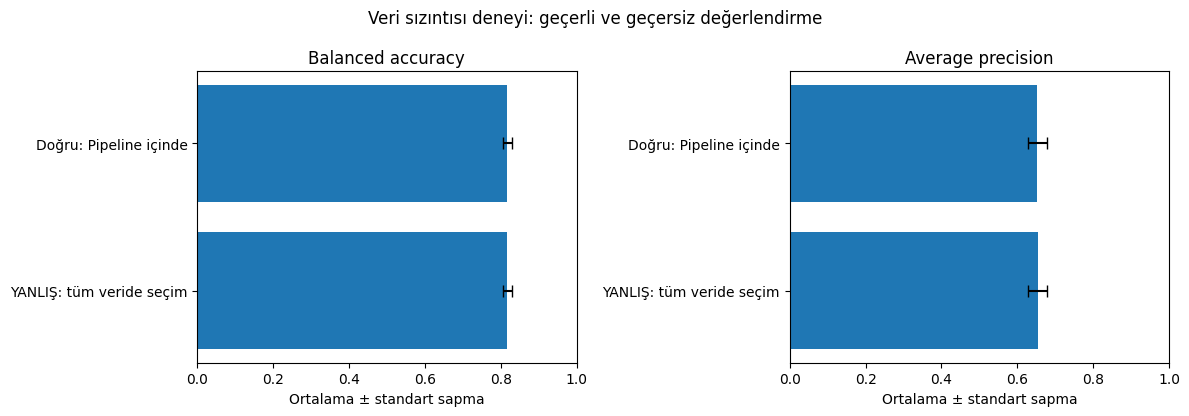

Grafik yorumu: Aynı CV katlarında ön işlemenin sırası karşılaştırıldı.
UYARI: YANLIŞ kurulumun skorları nihai model seçimi için kullanılamaz.


In [ ]:
# BÖLÜM 1.5 — KONTROLLÜ VERİ SIZINTISI DENEYİ
# Aynı özellikler, seçim metodu, model ve CV katları; yalnızca işlem sırası farklı.
# Orijinal X, y ve df DEĞİŞTİRİLMEZ.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

print("=== 1.5 ÖN İŞLEME + HEDEFE BAĞLI SEÇİM: DOĞRU / YANLIŞ ===")
category_cols_15 = [
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend"
]
numeric_cols_15 = [c for c in X.columns if c not in category_cols_15]

def make_preprocessor_15():
    return ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_cols_15),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
         category_cols_15)
    ])

def make_classifier_15():
    return LogisticRegression(
        class_weight="balanced", max_iter=2000, random_state=SEED
    )

# CV indeksleri bir kez oluşturulup iki yöntem için birebir aynı tutulur.
cv_15 = list(RepeatedStratifiedKFold(
    n_splits=5, n_repeats=2, random_state=SEED
).split(X, y))
metrics_15 = {
    "balanced_accuracy": "balanced_accuracy",
    "average_precision": "average_precision"
}

# DOĞRU: tüm dönüşümler yalnızca eğitim katında öğrenilir.
correct_pipeline_15 = Pipeline([
    ("preprocessing", make_preprocessor_15()),
    ("selection", SelectKBest(score_func=f_classif, k=10)),
    ("model", make_classifier_15())
])
correct_scores_15 = cross_validate(
    correct_pipeline_15, X, y, cv=cv_15, scoring=metrics_15,
    n_jobs=1, error_score="raise"
)

# YANLIŞ: doğrulama katları daha oluşturulmadan veri+etiketle seçim yapılır.
# Gerçek model değerlendirmesi için kesinlikle kullanılmamalıdır.
wrong_preprocessor_15 = make_preprocessor_15()
X_all_preprocessed_15 = wrong_preprocessor_15.fit_transform(X)
wrong_selector_15 = SelectKBest(score_func=f_classif, k=10)
X_all_selected_15 = wrong_selector_15.fit_transform(X_all_preprocessed_15, y)
wrong_scores_15 = cross_validate(
    make_classifier_15(), X_all_selected_15, y,
    cv=cv_15, scoring=metrics_15, n_jobs=1, error_score="raise"
)

# Her metrik için 10 katın ortalaması ve örnek standart sapması
rows_15 = []
for label, scores in [
    ("Doğru: Pipeline içinde", correct_scores_15),
    ("YANLIŞ: tüm veride seçim", wrong_scores_15)
]:
    row = {"Kurulum": label}
    for metric in metrics_15:
        v = scores["test_" + metric]
        row[metric + " ort"] = round(float(np.mean(v)), 4)
        row[metric + " std"] = round(float(np.std(v, ddof=1)), 4)
    rows_15.append(row)
leakage_results_15 = pd.DataFrame(rows_15)
display(leakage_results_15)

# Aynı katlardaki farkları ayrıca göster (yanlış - doğru)
paired_differences_15 = {}
for metric in metrics_15:
    gap = wrong_scores_15["test_" + metric] - correct_scores_15["test_" + metric]
    paired_differences_15[metric] = gap
    print(f"{metric}: yanlış - doğru = {gap.mean():+.4f} (ortalama), "
          f"ss={gap.std(ddof=1):.4f}; 10 katın {int((gap>0).sum())}'unda yanlış daha yüksek")

# Ortalama + standart sapma hata çubuklarıyla iki metrik için karşılaştırma
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, metric, title in zip(
    axes, metrics_15, ["Balanced accuracy", "Average precision"]
):
    v = leakage_results_15[metric + " ort"].to_numpy()
    sd = leakage_results_15[metric + " std"].to_numpy()
    ax.barh(leakage_results_15["Kurulum"], v, xerr=sd, capsize=4)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel("Ortalama ± standart sapma")
    ax.set_title(title)
fig.suptitle("Veri sızıntısı deneyi: geçerli ve geçersiz değerlendirme")
fig.tight_layout()
plt.show()
print("Grafik yorumu: Aynı CV katlarında ön işlemenin sırası karşılaştırıldı.")
print("UYARI: YANLIŞ kurulumun skorları nihai model seçimi için kullanılamaz.")


**Yorum — 1.5 Veri sızıntısı deneyi (Colab çıktılarıyla doğrulanmıştır)**

İki kurulum aynı **5 kat × 2 tekrar = 10 çapraz doğrulama katında**, aynı temel öznitelikler ve aynı lojistik regresyon modeli kullanılarak karşılaştırılmıştır. **Fark yalnızca ön işleme ve denetimli öznitelik seçiminin ne zaman öğrenildiğidir.**

| Ölçüt | Doğru: Pipeline içinde | Yanlış: bütün veride seçim |
|---|---:|---:|
| Balanced accuracy | **0,818 ± 0,0121** | **0,818 ± 0,0120** |
| Average precision | **0,6532 ± 0,0259** | **0,6534 ± 0,0260** |

- **Doğru kurulum:** Eksik değer doldurma, ölçekleme, kategorik kodlama ve denetimli `SelectKBest(k=10)` yalnızca eğitim katlarında öğrenilmiştir. Her dış katın doğrulama verisi bağımsız kalmıştır.
- **Yanlış kurulum:** Tüm veriye önce ön işleme ve `SelectKBest` uygulanmış, sonra çapraz doğrulama yapılmıştır. `SelectKBest` bütün hedef etiketlerine önceden baktığından doğrulama etiketleri seçime sızmıştır. Bu skorlar **nihai model seçimi için kullanılamaz.**
- **Gözlenen fark (yanlış − doğru):** Balanced accuracy için yaklaşık **+0,0001** (10 katın 2'sinde yanlış daha yüksek), average precision için yaklaşık **+0,0002** (10 katın 3'ünde yanlış daha yüksek). Balanced accuracy tablosu üç ondalığa yuvarlandığından iki ortalama aynı görünür.
- **Alan yorumu:** Bu veri, model ve seçilen `k` değeri için sızıntının etkisi küçüktür. Ancak sızıntı her veri setinde yüksek bir puan üretmek zorunda değildir. Metodolojik hata **puan farkının büyüklüğünden değil, doğrulama etiketlerinin önceden kullanılmış olmasından** kaynaklanır.
- **Sınırlılıklar:** Bu sonuçlar katlar arasında tamamen bağımsız olmayan, tekrarlı çapraz doğrulama skorlarıdır. Tek başlarına bağımsız dış test kanıtı ya da sızıntı etkisinin genel büyüklüğü değildir. 125 yinelenen satırın katlara dağılma etkisi sonraki model değerlendirmesinde ayrıca ele alınacaktır.


### 1.6 Baseline ve ilk model — DummyClassifier ve lojistik regresyon

Bir sınıflandırma modelinin, **hiçbir girdiyi kullanmadan çoğunluk sınıfını tahmin eden basit bir referanstan (baseline)** daha yararlı olup olmadığını inceliyoruz.

- **Baseline:** `DummyClassifier(strategy="prior")` yalnızca eğitim katındaki hedef sınıfının oranını öğrenir. Bu sınıf dengesizliğinde accuracy yüksek olabilir; balanced accuracy ve average precision bu nedenle birlikte raporlanır.
- **İlk model:** `LogisticRegression(class_weight="balanced")` tüm 17 girdi özelliğini kullanır; sayısal veriler ortanca ile tamamlanıp ölçeklenir, nominal özellikler one-hot olarak kodlanır.
- **Sızıntı önlemi:** Her iki modelde tüm ön işleme adımları `Pipeline` içinde eğitim katına özel olarak öğrenilir.
- **Değerlendirme:** Her iki yönteme **aynı** 5 kat × 2 tekrarlı katmanlı çapraz doğrulama bölmeleri uygulanır; accuracy, balanced accuracy, F1 ve average precision için **ortalama ± standart sapma** hesaplanır.

**Not:** Burada `accuracy`, çoğunluk sınıfı etkisini göstermek için *yalnızca ek bilgi* olarak sunulur; model seçimi tek başına bu ölçüte dayanmaz. Yinelenen oturumların değerlendirmeye etkisini ilerleyen aşamada ayrıca inceleyeceğiz.


=== 1.6 DUMMY / LOJİSTİK REGRESYON (5 KAT × 2 TEKRAR) ===


,Model,accuracy ort,accuracy std,balanced_accuracy ort,balanced_accuracy std,f1 ort,f1 std,average_precision ort,average_precision std
0,Baseline — Dummy (prior),0.8453,0.0002,0.5000,0.0000,0.0000,0.0000,0.1547,0.0002
1,İlk model — Lojistik regresyon,0.8483,0.0061,0.8126,0.0122,0.6081,0.0144,0.6499,0.0245


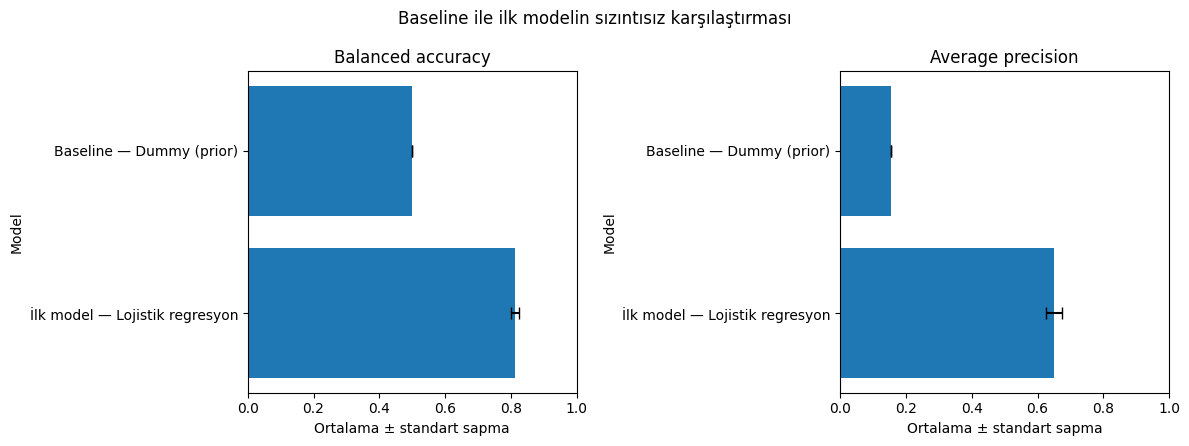

Grafik yorumu: Aynı katlarda Dummy ve lojistik regresyon sonuçları karşılaştırıldı.
Uyarı: Tamamen aynı 125 satırın CV katlarına etkisi henüz ayrıca kontrol edilmedi.


In [ ]:
# BÖLÜM 1.6 — BASELINE VE İLK MODEL (sızıntısız, tekrarlı CV)
# X, y ve df değiştirilmez. Başka hücrelerdeki değişkenleri ezmemek için _16 soneki kullanılır.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_cols_16 = [
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend"
]
numeric_cols_16 = [col for col in X.columns if col not in categorical_cols_16]

def preprocessing_16():
    # Pipelines her doğrulama katında yalnızca ilgili eğitim verisiyle öğrenilir.
    return ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scale", StandardScaler())
        ]), numeric_cols_16),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encode", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_cols_16)
    ])

models_16 = {
    "Baseline — Dummy (prior)": Pipeline([
        ("prep", preprocessing_16()),
        ("model", DummyClassifier(strategy="prior"))
    ]),
    "İlk model — Lojistik regresyon": Pipeline([
        ("prep", preprocessing_16()),
        ("model", LogisticRegression(
            class_weight="balanced", max_iter=2000, random_state=SEED
        ))
    ])
}

cv_16 = list(RepeatedStratifiedKFold(
    n_splits=5, n_repeats=2, random_state=SEED
).split(X, y))
scoring_16 = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "f1": "f1",
    "average_precision": "average_precision"
}

rows_16 = []
raw_scores_16 = {}
for model_name, model_16 in models_16.items():
    scores_16 = cross_validate(
        model_16, X, y, cv=cv_16, scoring=scoring_16,
        n_jobs=1, error_score="raise"
    )
    raw_scores_16[model_name] = scores_16
    result_16 = {"Model": model_name}
    for metric_16 in scoring_16:
        values_16 = scores_16["test_" + metric_16]
        result_16[f"{metric_16} ort"] = round(float(values_16.mean()), 4)
        result_16[f"{metric_16} std"] = round(float(values_16.std(ddof=1)), 4)
    rows_16.append(result_16)

baseline_results_16 = pd.DataFrame(rows_16)
print("=== 1.6 DUMMY / LOJİSTİK REGRESYON (5 KAT × 2 TEKRAR) ===")
display(baseline_results_16)

# Seçilen temel ölçütler için ortalama ve standart sapma hata çubukları
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, metric, title in zip(
    axes,
    ["balanced_accuracy", "average_precision"],
    ["Balanced accuracy", "Average precision"]
):
    means = baseline_results_16[metric + " ort"].to_numpy()
    stds = baseline_results_16[metric + " std"].to_numpy()
    ax.barh(baseline_results_16["Model"], means, xerr=stds, capsize=4)
    ax.set_xlim(0, 1)
    ax.invert_yaxis()
    ax.set_xlabel("Ortalama ± standart sapma")
    ax.set_ylabel("Model")
    ax.set_title(title)
fig.suptitle("Baseline ile ilk modelin sızıntısız karşılaştırması")
fig.tight_layout()
plt.show()
print("Grafik yorumu: Aynı katlarda Dummy ve lojistik regresyon sonuçları karşılaştırıldı.")
print("Uyarı: Tamamen aynı 125 satırın CV katlarına etkisi henüz ayrıca kontrol edilmedi.")


**Yorum — 1.6 Baseline ve ilk model (Colab sonuçlarıyla doğrulanmıştır)**

**Amaç:** Hiçbir girdi özelliğini kullanmayan `DummyClassifier(strategy="prior")` ile tüm 17 girdi özelliğini kullanan, `class_weight="balanced"` ayarlı lojistik regresyon modelini aynı **5 kat × 2 tekrar** bölmelerinde karşılaştırmak. Her iki kurulumda ön işleme adımları eğitim katına özel `Pipeline` içinde tutulmuştur.

| Ölçüt | DummyClassifier (ortalama ± std) | Lojistik regresyon (ortalama ± std) |
|---|---:|---:|
| Accuracy | **0,8453 ± 0,0002** | **0,8483 ± 0,0061** |
| Balanced accuracy | **0,5000 ± 0,0000** | **0,8126 ± 0,0122** |
| F1 (satın alma=True sınıfı) | **0,0000 ± 0,0000** | **0,6081 ± 0,0144** |
| Average precision (satın alma=True sınıfı) | **0,1547 ± 0,0002** | **0,6499 ± 0,0245** |

**Bulgular:** Baseline modelinin **%84,53 accuracy** değeri, sınıf dengesizliğinden kaynaklanan yanıltıcı bir görünüm sunar. Model, satın alma (`Revenue=True`) sınıfını hiç tahmin etmediğinden pozitif sınıf F1 skoru sıfırdır ve balanced accuracy **0,50**'dir. Buna karşılık lojistik regresyonun balanced accuracy değeri **0,8126**, pozitif sınıf F1 değeri **0,6081**, average precision değeri **0,6499** olmuştur. Accuracy farkı yalnızca **0,0030** (0,30 yüzde puanı) iken balanced accuracy farkı **0,3126**'dır. Dolayısıyla modelin yararlılığını yalnızca accuracy ile değerlendirmek uygun değildir.

**Sınırlılıklar:** Değerler **10 çapraz doğrulama skoru** üzerinden ortalama ± örneklem standart sapmasıdır; henüz bağımsız bir dış test kümesinin performansını temsil etmez. Aynı girdi ve hedefe sahip 125 tekrar eden kaydın eğitim ve doğrulama katları arasında paylaşılmasının yaratabileceği olası iyimser yanlılık ayrıca incelenecektir. Dış Weka kontrolü bu Python sonucundan bağımsız raporlanacaktır.


### 1.7 Weka ile bağımsız kontrol — ZeroR ve J48 (10 kat çapraz doğrulama)

**Yönerge görevi:** Aynı UCI verisi üzerinde Weka Explorer ile **ZeroR** ve **J48** modellerini, **10 kat çapraz doğrulama** kullanarak değerlendirmek ve Python bulgularıyla tutarlılığını tartışmak. Bu analiz zorunludur ve Python sonuçlarının bir kopyası değil, **Weka'da gerçekten çalıştırılmış ayrı bir kontrol** olmalıdır.

**Colab'da yapacağımız hazırlık:** Aşağıdaki hücre 17 özelliği ve `Revenue` hedefini içeren, Weka'nın okuyabildiği **ARFF** dosyasını oluşturur. `OperatingSystems`, `Browser`, `Region` ve `TrafficType` sütunları sayısal kodlarla saklansa da **nominal** türde yazılır; `Revenue` hedefi dosyanın **son sütunudur**. Orijinal `X`, `y`, `df` değişmez. Dosya yalnızca Colab çalışma alanına çıkar; **ham veri GitHub'a yüklenmez**.

**Weka Explorer adımları (öğrenci tarafından bilgisayarda):**

1. Bu hücreyi çalıştır; **`BIL545_online_shoppers_weka.arff`** dosyasını bilgisayarına indir.
2. Weka **Explorer → Preprocess → Open file...** ile ARFF dosyasını aç. **12.330 instances**, **18 attributes**, **class = Revenue** (son sütun) olduğunu kontrol et.
3. **Classify → Choose → rules → ZeroR** seç. **Test options → Cross-validation → Folds: 10**, **Random seed: 42** (ilgili kontrol mevcutsa) ayarla ve **Start** bas. Sonuçları metin olarak sakla.
4. **Classify → Choose → trees → J48** seç. Varsayılan seçeneklerle **aynı 10 kat çapraz doğrulama** düzeninde **Start** bas. Sonuçları metin olarak sakla.
5. Weka çıktılarından **Correctly Classified Instances**, confusion matrix ve **Revenue=True için Precision, Recall, F-Measure, PRC Area** bilgilerini buraya aktar.

**Ayrım:** Weka `J48` (C4.5) ile Python'daki `DecisionTreeClassifier` (CART ailesi) aynı algoritma değildir; sonuçlarının aynı olması beklenmez. Weka ile Python'un katlara ayırma algoritmaları da aynı seed kullanılsa bile birebir aynı olmayabilir. Kıyaslamada en önemli noktalar **veri sayısı, hedef yönü, sınıf dengesizliği, ZeroR başarısı ve karar ağacı için sonuçların makul tutarlılığıdır**.

**Not:** Python tarafındaki aşağıdaki tablo **yalnızca referans** içindir; Weka deneyinin yerini tutmaz. Weka Apriori kontrolü Bölüm 3'te ayrıca yapılacaktır.


In [ ]:
# BÖLÜM 1.7 — WEKA İÇİN ARFF DOSYASI + PYTHON REFERANS KONTROLÜ
# Gerçek Weka ZeroR/J48 sonuçları Weka Explorer'da öğrenci tarafından üretilecektir.
# Orijinal veri tablosu değiştirilmez.
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.impute import SimpleImputer

weka_nominal_cols = ["Month", "OperatingSystems", "Browser", "Region",
                     "TrafficType", "VisitorType", "Weekend", "Revenue"]
weka_code_nominal = {"OperatingSystems", "Browser", "Region", "TrafficType"}
weka_data = X.copy(deep=True)
weka_data["Revenue"] = y.to_numpy()
assert weka_data.shape == (12330, 18)
assert list(weka_data.columns)[-1] == "Revenue"
assert set(weka_data["Revenue"].unique()) == {True, False}

# Nominal değerlerin Weka'da sayısal sıralama gibi algılanmasını engelle.
def weka_nominal_string(col, value):
    if pd.isna(value):
        return "?"
    if col in ("Weekend", "Revenue"):
        return "True" if bool(value) else "False"
    if col in weka_code_nominal:
        return "K" + str(int(value))  # ör. TrafficType=2 → K2 (kategori)
    val = str(value)
    if not val.replace("_", "").isalnum():
        raise ValueError(f"Beklenmeyen nominal değer: {col}={val!r}")
    return val

weka_levels = {}
for col in weka_nominal_cols:
    if col in ("Weekend", "Revenue"):
        weka_levels[col] = ["False", "True"]
    else:
        weka_levels[col] = sorted({
            weka_nominal_string(col, v)
            for v in weka_data[col].dropna().unique()
        })

# ARFF dosyasında özellik adları kaynak veridekiyle aynı tutulur.
arff_path_17 = Path("/content/BIL545_online_shoppers_weka.arff")
with arff_path_17.open("w", encoding="utf-8", newline="\n") as out:
    out.write("@RELATION online_shoppers_purchasing_intention\n\n")
    for col in weka_data.columns:
        if col in weka_nominal_cols:
            out.write("@ATTRIBUTE " + col + " {" + ",".join(weka_levels[col]) + "}\n")
        else:
            out.write("@ATTRIBUTE " + col + " NUMERIC\n")
    out.write("\n@DATA\n")
    for values in weka_data.itertuples(index=False, name=None):
        cells = []
        for col, v in zip(weka_data.columns, values):
            if col in weka_nominal_cols:
                cells.append(weka_nominal_string(col, v))
            elif pd.isna(v):
                cells.append("?")
            else:
                cells.append(format(float(v), ".15g"))
        out.write(",".join(cells) + "\n")

print("=== WEKA ARFF DOSYASI HAZIR ===")
print("Dosya:", arff_path_17.name)
print("Boyut (bayt):", arff_path_17.stat().st_size)
print("Kayıt / özellik + hedef:", weka_data.shape)
print("Hedef dağılımı:")
print(weka_data["Revenue"].value_counts())
print("İlk 6 ARFF başlık satırı:")
print("\n".join(arff_path_17.read_text(encoding="utf-8").splitlines()[:6]))
print("NOT: Bu dosya Weka'ya yerel olarak yüklenir, GitHub'a konmaz.")

# Python'da 10-kat referans: Weka J48 ile birebir aynı algoritma DEĞİLDİR.
weka_py_cats = [c for c in weka_nominal_cols if c != "Revenue"]
weka_py_nums = [c for c in X.columns if c not in weka_py_cats]
weka_py_preproc = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), weka_py_nums),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore"))
    ]), weka_py_cats)
])

reference_models_17 = {
    "Python Dummy(prior), ZeroR referansı": Pipeline([
        ("prep", weka_py_preproc),
        ("clf", DummyClassifier(strategy="prior"))
    ]),
    "Python DecisionTree(entropy), J48'e yaklaşık referans": Pipeline([
        ("prep", weka_py_preproc),
        ("clf", DecisionTreeClassifier(criterion="entropy",
                                       min_samples_leaf=2,
                                       random_state=SEED))
    ])
}
cv_17 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
metrics_17 = {"accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy",
              "f1": "f1", "average_precision": "average_precision"}
rows_17 = []
for model_name_17, model_17 in reference_models_17.items():
    output_17 = cross_validate(model_17, X, y, cv=cv_17,
                               scoring=metrics_17, n_jobs=1,
                               error_score="raise")
    result_17 = {"Model": model_name_17}
    for metric_17 in metrics_17:
        s_17 = output_17["test_" + metric_17]
        result_17[metric_17 + " ort"] = round(float(s_17.mean()), 4)
        result_17[metric_17 + " std"] = round(float(s_17.std(ddof=1)), 4)
    rows_17.append(result_17)

python_reference_17 = pd.DataFrame(rows_17)
print("\n=== PYTHON 10-KAT REFERANS TABLOSU (WEKA SONUCU DEĞİL) ===")
display(python_reference_17)
print("Weka'da ayrıca ZeroR ve J48'i 10-kat CV ile çalıştırın.")

# Colab kullanılıyorsa yerel Weka için ARFF indirmeyi başlat.
from google.colab import files
files.download(str(arff_path_17))


=== WEKA ARFF DOSYASI HAZIR ===
Dosya: BIL545_online_shoppers_weka.arff
Boyut (bayt): 1109664
Kayıt / özellik + hedef: (12330, 18)
Hedef dağılımı:
Revenue
False    10422
True      1908
Name: count, dtype: int64
İlk 6 ARFF başlık satırı:
@RELATION online_shoppers_purchasing_intention

@ATTRIBUTE Administrative NUMERIC
@ATTRIBUTE Administrative_Duration NUMERIC
@ATTRIBUTE Informational NUMERIC
@ATTRIBUTE Informational_Duration NUMERIC
NOT: Bu dosya Weka'ya yerel olarak yüklenir, GitHub'a konmaz.

=== PYTHON 10-KAT REFERANS TABLOSU (WEKA SONUCU DEĞİL) ===


,Model,accuracy ort,accuracy std,balanced_accuracy ort,balanced_accuracy std,f1 ort,f1 std,average_precision ort,average_precision std
0,"Python Dummy(prior), ZeroR referansı",0.8453,0.0003,0.5000,0.0000,0.0000,0.0000,0.1547,0.0003
1,"Python DecisionTree(entropy), J48'e yaklaşık r...",0.8689,0.0079,0.7373,0.0122,0.5634,0.0206,0.4177,0.0199


Weka'da ayrıca ZeroR ve J48'i 10-kat CV ile çalıştırın.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Yorum — 1.7 Weka bağımsız kontrol (Weka ve Python çıktılarıyla doğrulanmıştır)**

**Kurulumun bağımsızlığı:** Weka Explorer üzerinde `online_shoppers_purchasing_intention` ARFF verisindeki **12.330 oturum, 17 girdi ve `Revenue` hedefi** kullanılarak ZeroR ve J48, **10 katlı çapraz doğrulama** ile gerçekten çalıştırılmıştır. Weka nominal kodlar ARFF'de kategorik olarak tanımlanmıştır. Kanıt: öğrenci tarafından sunulan `ZeroR.docx` ve `J48.docx` Weka çıktıları; aşağıdaki sayılar bu dosyalardan alınmıştır. Bu çıktıların özeti burada tutulmaktadır.

**Weka'da raporlanan sonuçlar:**

| 10 katlı CV ölçütü | ZeroR | J48 (`-C 0.25 -M 2`) |
|---|---:|---:|
| Doğru sınıflandırılmış oturum | **10.422 / 12.330** | **11.062 / 12.330** |
| Accuracy | **%84,5255** | **%89,7161** |
| Balanced accuracy (hata matrisinden hesaplanan) | **0,5000** | **0,7660** |
| `Revenue=True` precision | Tanımsız (pozitif tahmin yok) | **0,705** |
| `Revenue=True` recall | **0,000** | **0,576** |
| `Revenue=True` F1 | **0 / Weka'da tanımsız gösterilebilir** | **0,634** |
| `Revenue=True` PRC Area (Weka) | **0,155** | **0,566** |

**Confusion matrix — gerçek satırlar, tahmin sütunlar (`False`, `True`):**

- **ZeroR:** `[[10422, 0], [1908, 0]]` — bütün oturumları `False` tahmin ediyor. Satın alma olaylarının hiçbirini yakalamadığı için accuracy=%84,53 yanıltıcı biçimde yüksek görünüyor.
- **J48:** `[[9963, 459], [809, 1099]]` — 1.908 gerçek satın alma oturumunun **1.099'unu** yakalıyor; **809** satın almayı kaçırıyor, **459** satın alınmayan oturumu satın alındı olarak işaretliyor. `True` recall = `1099/1908 ≈ 0,576`, `False` recall = `9963/10422 ≈ 0,956`; bunların ortalaması **0,7660** balanced accuracy'dir.

**Karar ağacının yorumlanması:** Weka'nın tam veriden kurduğu budanmış J48 ağacında ilk bölme **`PageValues <= 0.038035`** koşuludur; modelde **336 yaprak** ve **448 düğüm/boyut** raporlanır. Bu, `PageValues` değişkeninin ağaçta güçlü bir ilk ayırım sağladığını gösterir, tek başına nedensellik veya sızıntı kanıtı değildir. Özelliğin oturumun hangi anında bilindiği, gerçek zamanlı tahmin iddiası için ayrıca değerlendirilmelidir.

**Python ile bağımsız tutarlılık denetimi (aynı notebook'taki gerçek 10-kat CV çıktısı):**

| Python referans modeli | Accuracy, ort ± std | Balanced accuracy, ort ± std | F1 (`Revenue=True`), ort ± std | Average precision, ort ± std |
|---|---:|---:|---:|---:|
| Dummy (`prior`) | 0,8453 ± 0,0003 | 0,5000 ± 0,0000 | 0,0000 ± 0,0000 | 0,1547 ± 0,0003 |
| DecisionTree (`entropy`) | 0,8689 ± 0,0079 | 0,7373 ± 0,0122 | 0,5634 ± 0,0206 | 0,4177 ± 0,0199 |

**Tutarlılık ve farkların açıklaması:** ZeroR ile Python Dummy, çoğunluk sınıfına yöneldikleri için neredeyse aynı genel doğruluğu ve 0,50 dengeli doğruluğu verir. Her iki ortamda karar ağacı yaklaşımı bu baseline'ı iyileştirir. Weka **J48 (C4.5, budamalı)** ile Python **DecisionTreeClassifier (CART türü, `criterion="entropy"`)** aynı algoritma değildir; Weka ve Python'un doğrulama katları da birebir eşleşmeyebilir. Bu nedenle Weka'daki %89,72 ile Python'daki %86,89 arasındaki farkı doğrudan hata veya üstünlük kanıtı olarak yorumlamıyoruz. Weka'nın **PRC Area** değeriyle Python'un **average precision** ölçütü de birebir aynı hesaplanmak zorunda değildir; iki sayıyı aynı ölçümmüş gibi çıkarmıyoruz.

**Sınırlılıklar:** Weka'nın 10-kat CV raporu bütün katların birleştirilmiş toplamına dayanır; Python'da ise 10 kat için ayrı skorların **ortalama ± standart sapması** raporlanmıştır. Tek Weka özetinden kat bazında standart sapma uydurulmamıştır. Ayrıca veri setindeki **125 yinelenen kayıt** bu Weka deneyi sırasında grup-bazlı ayrılmamıştır. Sonraki bölümde bu riski azaltmak üzere aynı girdi satırlarını aynı doğrulama grubunda tutan bir karşılaştırma kurulacaktır. Weka Apriori kontrolü Bölüm 3'te ayrıca yapılacaktır.


# Bölüm 2 · Sınıflandırma ve dürüst model değerlendirme *(ağırlık 30)*
**Makale:** Dietterich (1998). Approximate statistical tests for comparing supervised classification learning algorithms. *Neural Computation*, 10(7).

**Okuma notu (3–4 cümle):** …

### 2.1 Model karşılaştırması — tekrarlı ve grup-korumalı çapraz doğrulama

**Amaç:** Baseline, karar ağacı, k-en yakın komşu (k-NN), rastgele orman (Random Forest) ve bir gradyan artırma modeli (Histogram-based Gradient Boosting) arasında **dürüst bir karşılaştırma** yapmak.

- **Sınıf dengesizliği:** `Revenue=True` oranı yaklaşık **%15,47** olduğundan ana karşılaştırma ölçütü **average precision** (precision–recall eğrisini özetler); ikincil ölçüt **balanced accuracy**. F1 ve accuracy destekleyici olarak gösterilir.
- **Tekrarlı doğrulama:** **5 kat × 2 tekrar = 10 bölme** uygulanır. Önceki analizde tespit edilen **125 yinelenen girdi satırının** eğitim ve doğrulama arasında ayrılmaması için `StratifiedGroupKFold` kullanılarak, aynı özellikleri taşıyan kayıtlar aynı grupta tutulur. Bu, tekrarlı ve olabildiğince katmanlı bir **grup-korumalı** doğrulama yöntemidir. Bölmeler bütün modeller için ortaktır.
- **Pipeline:** Her model için eksik değer doldurma, sayısal ölçekleme ve kategorik kodlama yalnızca eğitim katında öğrenilir; bütün tabloda ön işleme yapılmaz.
- **Modeller:** `DummyClassifier`, sınırlandırılmış `DecisionTreeClassifier`, `KNeighborsClassifier`, `RandomForestClassifier`, `HistGradientBoostingClassifier`. Parametreler bu ilk karşılaştırma için **önceden sabitlenmiştir**; bu tabloda sonuçlara bakarak hiperparametre ayarı yapılmaz.
- **Raporlama:** Her ölçütte **ortalama ± standart sapma**, ayrıca average precision için **kutu grafiği** ve modellerin sıralaması. En iyi model seçimi Bölüm 2.5'te ayrıntılı gerekçelendirilecek; optimist yanlılık ve istatistiksel testler Bölüm 2.3–2.4'te yapılacaktır.

**Kısıt:** Bu 10 skor bağımsız bir dış test kümesi değildir. Grup-korumalı doğrulama, yalnızca **tamamen aynı girdi satırlarından kaynaklanan** sızıntı riskini azaltır; gerçek kullanıcı kimlikleri verilmediği için aynı kişinin farklı oturumlarının gruplar arasında bulunmadığı garanti edilemez.


Toplam oturum: 12330
Aynı girdilere sahip yinelenen satır: 125
Benzersiz girdi grubu: 12205
Toplam CV bölmesi: 10 (5 kat × 2 tekrar)
Çalıştırılıyor: Baseline / Dummy
Çalıştırılıyor: Karar ağacı
Çalıştırılıyor: k-NN
Çalıştırılıyor: Rastgele orman
Çalıştırılıyor: Gradient Boosting

=== 2.1 MODEL KARŞILAŞTIRMASI (ortalama ± standart sapma) ===


,Model,average_precision ort,average_precision std,balanced_accuracy ort,balanced_accuracy std,f1 ort,f1 std,accuracy ort,accuracy std
0,Gradient Boosting,0.7571,0.0161,0.7850,0.0126,0.6655,0.0189,0.9049,0.0071
1,Rastgele orman,0.7339,0.0206,0.8302,0.0100,0.6815,0.0141,0.8932,0.0060
2,Karar ağacı,0.6664,0.0203,0.8343,0.0076,0.6214,0.0233,0.8451,0.0170
3,k-NN,0.5900,0.0280,0.6561,0.0148,0.4598,0.0329,0.8787,0.0091
4,Baseline / Dummy,0.1547,0.0069,0.5000,0.0000,0.0000,0.0000,0.8453,0.0069


/tmp/ipykernel_1069/2955954327.py:111: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(score_vectors_21, vert=False, labels=ordered_names_21,


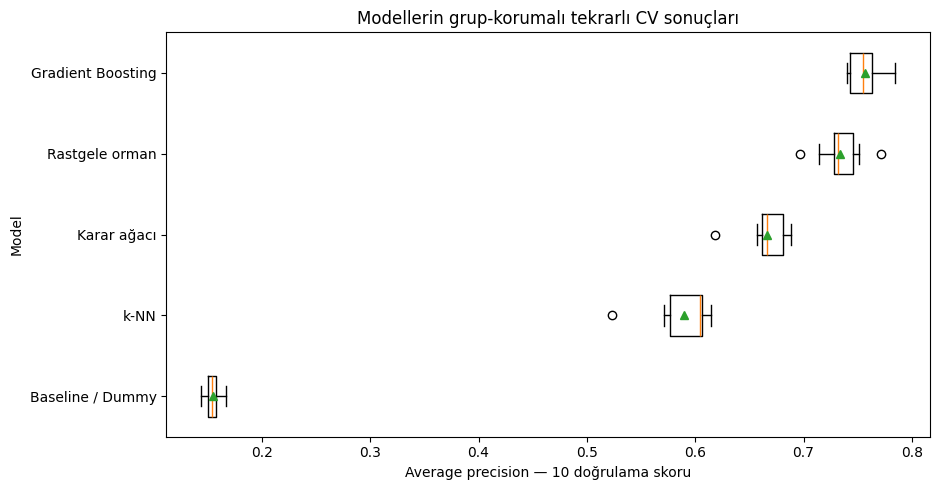

Grafik yorumu: Kutu ve saçaklar 10 katın dağılımını; kesikli işaretler ortalamayı gösterir.
Not: Bu skorlar bağımsız test seti performansı değildir.


In [ ]:
# BÖLÜM 2.1 — BEŞ MODELİN ADİL KARŞILAŞTIRMASI
# 5 kat × 2 tekrar; grup-korumalı doğrulama ile 125 aynı girdi tekrarının ayrılması önlenir.
# Bu bölüm ORİJİNAL X ve y üzerinde çalışır; hiçbir deney bunları kalıcı olarak değiştirmez.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

categorical_cols_21 = [
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend"
]
numeric_cols_21 = [c for c in X.columns if c not in categorical_cols_21]

# Tamamen aynı girdi vektörleri aynı gruba atanır. Hedef kesinlikle grup koduna girmez.
groups_21 = pd.util.hash_pandas_object(X, index=False).to_numpy()
print("Toplam oturum:", len(X))
print("Aynı girdilere sahip yinelenen satır:", int(X.duplicated().sum()))
print("Benzersiz girdi grubu:", int(pd.Series(groups_21).nunique()))

# Aynı grup hiçbir tekrarda train ve validation arasında bölünmeyecek.
cv_splits_21 = []
for repeat_21 in range(2):
    splitter_21 = StratifiedGroupKFold(
        n_splits=5, shuffle=True, random_state=SEED + repeat_21
    )
    for train_idx_21, val_idx_21 in splitter_21.split(X, y, groups_21):
        assert not set(groups_21[train_idx_21]).intersection(
            set(groups_21[val_idx_21])
        ), "Aynı girdi grubu iki tarafta!"
        cv_splits_21.append((train_idx_21, val_idx_21))
assert len(cv_splits_21) == 10
print("Toplam CV bölmesi:", len(cv_splits_21), "(5 kat × 2 tekrar)")

# Yoğun one-hot çıktı, HistGradientBoosting için gereklidir.
# 12.330 kayıt × sınırlı kategori sayısıyla Colab RAM bakımından uygulanabilir.
def preprocessor_21():
    return ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scale", StandardScaler())
        ]), numeric_cols_21),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ]), categorical_cols_21)
    ], sparse_threshold=0)

model_definitions_21 = {
    "Baseline / Dummy": DummyClassifier(strategy="prior"),
    "Karar ağacı": DecisionTreeClassifier(
        max_depth=8, min_samples_leaf=10, class_weight="balanced", random_state=SEED
    ),
    "k-NN": KNeighborsClassifier(n_neighbors=15, weights="distance"),
    "Rastgele orman": RandomForestClassifier(
        n_estimators=150, min_samples_leaf=3,
        class_weight="balanced_subsample", random_state=SEED, n_jobs=1
    ),
    "Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=100, learning_rate=0.07, max_leaf_nodes=15,
        l2_regularization=0.2, random_state=SEED
    ),
}

scoring_21 = {
    "average_precision": "average_precision",
    "balanced_accuracy": "balanced_accuracy",
    "f1": "f1",
    "accuracy": "accuracy"
}

comparison_rows_21 = []
raw_scores_21 = {}
for name_21, clf_21 in model_definitions_21.items():
    print("Çalıştırılıyor:", name_21)
    pipeline_21 = Pipeline([
        ("prep", preprocessor_21()),
        ("model", clf_21)
    ])
    score_21 = cross_validate(
        pipeline_21, X, y, cv=cv_splits_21, scoring=scoring_21,
        n_jobs=1, error_score="raise"
    )
    raw_scores_21[name_21] = score_21
    item_21 = {"Model": name_21}
    for metric_21 in scoring_21:
        vals_21 = score_21["test_" + metric_21]
        item_21[metric_21 + " ort"] = round(float(vals_21.mean()), 4)
        item_21[metric_21 + " std"] = round(float(vals_21.std(ddof=1)), 4)
    comparison_rows_21.append(item_21)

comparison_results_21 = pd.DataFrame(comparison_rows_21)
comparison_results_21 = comparison_results_21.sort_values(
    by="average_precision ort", ascending=False
).reset_index(drop=True)
print("\n=== 2.1 MODEL KARŞILAŞTIRMASI (ortalama ± standart sapma) ===")
display(comparison_results_21)

ordered_names_21 = comparison_results_21["Model"].tolist()
score_vectors_21 = [raw_scores_21[name]["test_average_precision"]
                    for name in ordered_names_21]
fig, ax = plt.subplots(figsize=(9.5, 5))
ax.boxplot(score_vectors_21, vert=False, tick_labels=ordered_names_21,
           showmeans=True)
ax.invert_yaxis()
ax.set_xlabel("Average precision — 10 doğrulama skoru")
ax.set_ylabel("Model")
ax.set_title("Modellerin grup-korumalı tekrarlı CV sonuçları")
fig.tight_layout()
plt.show()
print("Grafik yorumu: Kutu ve saçaklar 10 katın dağılımını; kesikli işaretler ortalamayı gösterir.")
print("Not: Bu skorlar bağımsız test seti performansı değildir.")


**Yorum — 2.1 Model karşılaştırması (Colab sonuçlarıyla doğrulandı)**

**Deney düzeni:** UCI Online Shoppers verisindeki **12.330 oturum** için **5 kat × 2 tekrar = 10** doğrulama bölmesi oluşturulmuştur. **125 yinelenen girdi kaydı** aynı özelliklere göre gruplanarak eğitim ve doğrulama katlarının iki tarafına düşmesi önlenmiştir (`StratifiedGroupKFold`). Tüm modeller aynı bölmelerde karşılaştırılmıştır. Gruplama gerçek kullanıcı kimliğine dayanmadığından aynı kişinin farklı oturumları için tam izolasyon garantisi vermez.

**Ana ölçüt:** Satın alma sınıfı yalnızca %15,47 olduğundan **average precision** ana seçim ölçütüdür. Diğer ölçütler olası ödünleşimleri değerlendirmek için raporlanmıştır. Aşağıdaki değerler **10 CV skorunun ortalaması ± standart sapmasıdır**:

| Model | Average precision | Balanced accuracy | F1 | Accuracy |
|---|---:|---:|---:|---:|
| **Gradient Boosting** | **0,7571 ± 0,0161** | 0,7850 ± 0,0126 | 0,6655 ± 0,0189 | **0,9049 ± 0,0071** |
| **Rastgele orman** | 0,7339 ± 0,0206 | 0,8302 ± 0,0100 | **0,6815 ± 0,0141** | 0,8932 ± 0,0060 |
| Karar ağacı | 0,6664 ± 0,0203 | **0,8343 ± 0,0076** | 0,6214 ± 0,0233 | 0,8451 ± 0,0170 |
| k-NN | 0,5900 ± 0,0280 | 0,6561 ± 0,0148 | 0,4598 ± 0,0329 | 0,8787 ± 0,0091 |
| Baseline / Dummy | 0,1547 ± 0,0069 | 0,5000 ± 0,0000 | 0,0000 ± 0,0000 | 0,8453 ± 0,0069 |

**İki öncü aday:** Average precision ölçütünde **Gradient Boosting birinci**, **Random Forest ikinci** olmuştur. Ortalama fark **0,0232**'dir. Kutu grafiği, bölmeler arasında performans değişkenliği ve iki adayın bazı skorlarının örtüştüğünü göstermektedir. Bu nedenle yalnızca ortalamaların karşılaştırılmasıyla **istatistiksel anlamlılık iddia edilmez**. İstatistiksel karşılaştırma Bölüm 2.4'te yapılacaktır.

**Farklı ölçütlerin yorumu:** Random Forest, Gradient Boosting'den daha yüksek F1 (**0,6815'e karşı 0,6655**) ve balanced accuracy (**0,8302'ye karşı 0,7850**) elde etmiştir. Karar ağacı ise en yüksek balanced accuracy (**0,8343**) sonucunu vermiştir. Bu durum, ana ölçüt seçiminin model sıralamasını etkilediğini ortaya koymaktadır. Yüksek accuracy tek başına yeterli değildir: Dummy'nin accuracy değeri %84,53 olsa da F1'i sıfırdır.

**Yöntemsel sınırlar:** Bu modellerin parametreleri ön karşılaştırma için sabit tutulmuştur. Skorlar **bağımsız bir test kümesinden gelmemektedir**; tekrarlı katlar arasında bağımlılık vardır. Adayların hiperparametre ayarları, iç içe doğrulama ve istatistiksel testler tamamlanmadan nihai bir üstünlük veya dağıtıma hazır model iddia edilmez. **Geçici lider** ana ölçüte göre Gradient Boosting'dir.


### 2.2 Karar ağacının yorumlanması — kök ve ilk iki derinlik

**Amaç:** 2.1'deki karar ağacının nasıl sınıflandırma yaptığına dair açıklanabilir bir örnek üretmek. 2.1 ile **aynı karar ağacı hiperparametreleri** kullanılacak. Tamamen aynı girdi kayıtları birbirinden ayrılmayacak biçimde ilk grup-korumalı CV bölmesinin **yalnızca eğitim kısmı** üzerinde model kurulacak; böylece yorumlamak için doğrulama etiketlerine başvurulmayacak.


Eğitilmiş ağacın kökü ve **derinlik 0–2** (ilk iki ayrım düzeyi) `export_text` ve görsel ile gösterilecektir. Başlıca bölme değişkenleri ve eşikleri açıklanacak. Tam ağacın tüm dalları değil, kolay yorumlanabilen ilk kısmı sunulur.

**Sınırlılık:** İlk bölmelerin açıklaması **nedensellik kanıtı değildir**. Özellikle `PageValues`, `ExitRates`, `BounceRates` gibi oturum içi/sonunda hesaplanabilen özellikler için gerçek zamanlı erken tahmin iddiasında bulunulamaz. Tek bir eğitim katında oluşturulan ağacın ilk dalları tüm CV katlarında sabit olmak zorunda değildir.


Eğitim oturumu: 9855 | ayrılan doğrulama oturumu: 2475
Ağaç derinliği: 8 | yaprak sayısı: 128

=== KÖK VE İLK İKİ DERİNLİK (export_text) ===
|--- num__PageValues <= -0.3191
|   |--- cat__Month_Nov <= 0.5000
|   |   |--- num__Administrative_Duration <= -0.4455
|   |   |   |--- truncated branch of depth 6
|   |   |--- num__Administrative_Duration >  -0.4455
|   |   |   |--- truncated branch of depth 6
|   |--- cat__Month_Nov >  0.5000
|   |   |--- num__ProductRelated_Duration <= 0.0367
|   |   |   |--- truncated branch of depth 6
|   |   |--- num__ProductRelated_Duration >  0.0367
|   |   |   |--- truncated branch of depth 6
|--- num__PageValues >  -0.3191
|   |--- num__BounceRates <= -0.4465
|   |   |--- num__PageValues <= 0.3326
|   |   |   |--- truncated branch of depth 6
|   |   |--- num__PageValues >  0.3326
|   |   |   |--- truncated branch of depth 6
|   |--- num__BounceRates >  -0.4465
|   |   |--- cat__Month_Nov <= 0.5000
|   |   |   |--- truncated branch of depth 6
|   |   |---

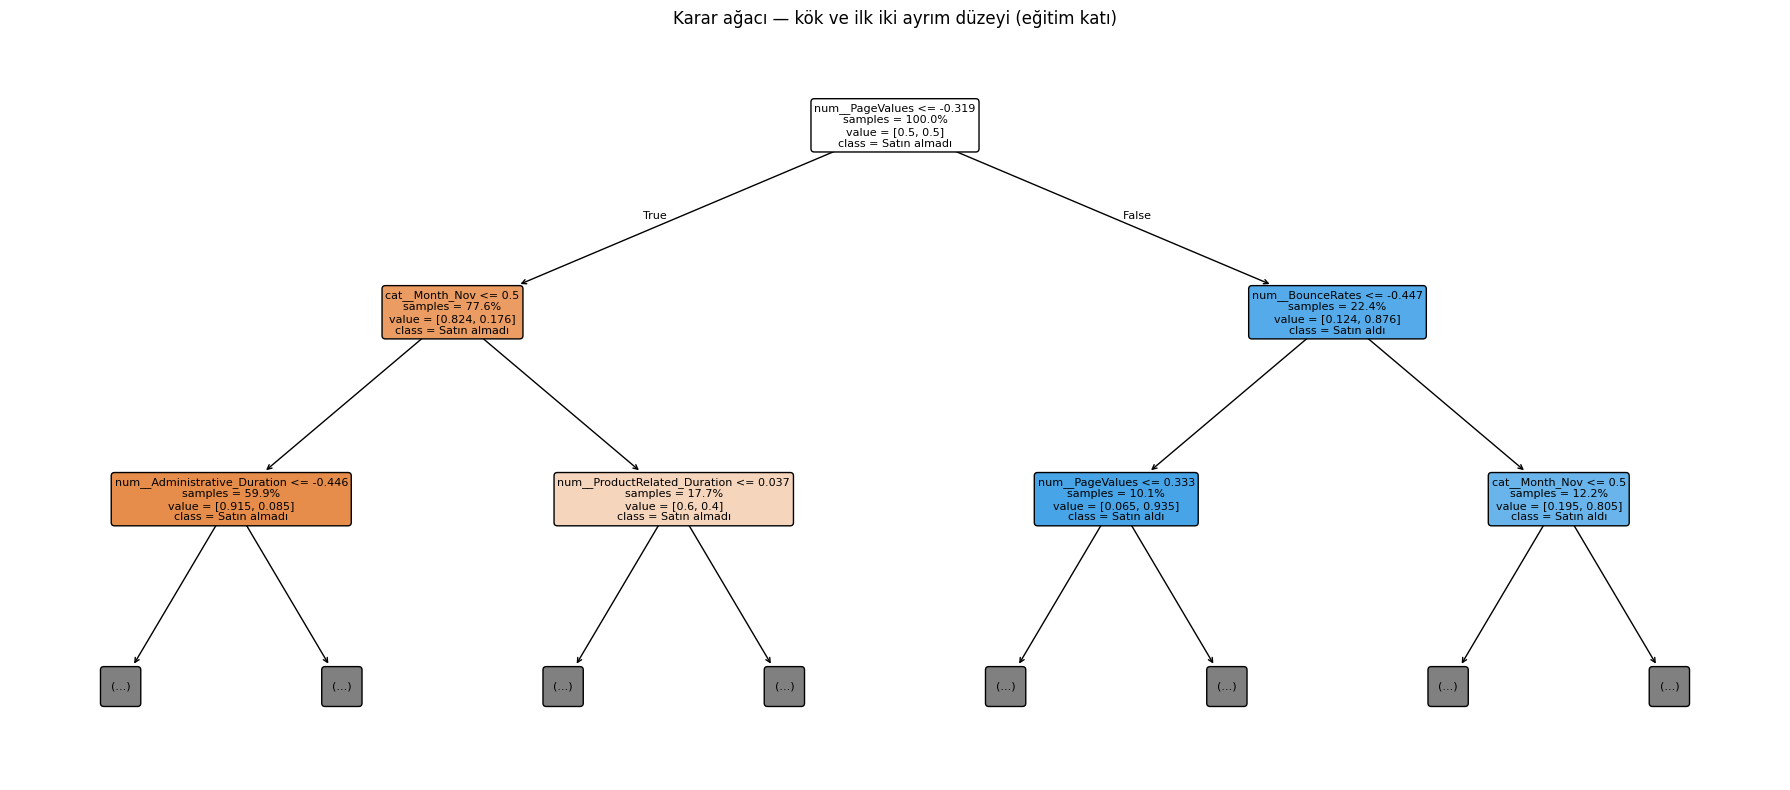

Grafik yorumu: Kökteki ve ilk iki düzeydeki koşullar, bu eğitim katındaki sınıflandırma yolunu açıklar.
Kök ayrım: num__PageValues <= -0.3191 (model dönüşümü sonrası)
Not: Sayısal özellikler ölçeklendiği için ekrandaki eşikler ham ölçü birimlerinde olmayabilir.

En yüksek öneme sahip ilk 10 dönüştürülmüş özellik:


,Dönüştürülmüş özellik,Önem
0,num__PageValues,0.7396
1,cat__Month_Nov,0.0717
2,num__ProductRelated_Duration,0.0482
3,num__ExitRates,0.0244
4,num__BounceRates,0.0229
5,num__Administrative_Duration,0.0171
6,cat__Month_May,0.0118
7,num__ProductRelated,0.0116
8,num__Administrative,0.0113
9,cat__Month_Mar,0.0100


Önem puanları yalnızca bu ağacın eğitiminde kullanılan bölmelere ilişkindir; nedensellik göstermez.


In [ ]:
# BÖLÜM 2.2 — KARAR AĞACININ KÖKÜNÜ VE İLK İKİ DÜZEYİNİ YORUMLAMA
# Bu hücre yalnızca Hazırlık + Veri Yükleme hücreleri çalıştırıldıysa da çalışabilir.
# X, y, df üzerinde değişiklik yapmaz; 2.1'deki ağacın hiperparametrelerini korur.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree, _tree

SEED_22 = globals().get("SEED", 42)
cat_cols_22 = ["Month", "OperatingSystems", "Browser", "Region",
               "TrafficType", "VisitorType", "Weekend"]
num_cols_22 = [col for col in X.columns if col not in cat_cols_22]

# Tamamen aynı girdileri aynı grupta tut; hedef grup anahtarına katılmaz.
groups_22 = pd.util.hash_pandas_object(X, index=False).to_numpy()
fold_22 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED_22)
train_idx_22, val_idx_22 = next(fold_22.split(X, y, groups_22))
assert not set(groups_22[train_idx_22]) & set(groups_22[val_idx_22])

preprocessor_22 = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), num_cols_22),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]), cat_cols_22)
], sparse_threshold=0)

# 2.1'deki karar ağacının aynı hiperparametreleri.
tree_pipeline_22 = Pipeline([
    ("prep", preprocessor_22),
    ("tree", DecisionTreeClassifier(
        max_depth=8, min_samples_leaf=10,
        class_weight="balanced", random_state=SEED_22
    ))
])
tree_pipeline_22.fit(X.iloc[train_idx_22], y.iloc[train_idx_22])
trained_prep_22 = tree_pipeline_22.named_steps["prep"]
trained_tree_22 = tree_pipeline_22.named_steps["tree"]
feature_names_22 = trained_prep_22.get_feature_names_out().tolist()
print("Eğitim oturumu:", len(train_idx_22), "| ayrılan doğrulama oturumu:", len(val_idx_22))
print("Ağaç derinliği:", trained_tree_22.get_depth(),
      "| yaprak sayısı:", trained_tree_22.get_n_leaves())
print("\n=== KÖK VE İLK İKİ DERİNLİK (export_text) ===")
print(export_text(trained_tree_22, feature_names=feature_names_22,
                  max_depth=2, decimals=4))

# İlk üç derinliğin ağacını görselleştir (derinlik 0 kök, 1 ve 2 dallar).
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(trained_tree_22, feature_names=feature_names_22,
          class_names=["Satın almadı", "Satın aldı"],
          max_depth=2, filled=True, rounded=True, fontsize=8,
          impurity=False, proportion=True, ax=ax)
ax.set_title("Karar ağacı — kök ve ilk iki ayrım düzeyi (eğitim katı)")
fig.tight_layout()
plt.show()
print("Grafik yorumu: Kökteki ve ilk iki düzeydeki koşullar, bu eğitim katındaki sınıflandırma yolunu açıklar.")

# Kök koşulunu otomatik yazdır; sayısal özniteliklerde StandardScaler nedeniyle
# bu eşik standardize uzaydadır, doğrudan ham değişken biriminde değildir.
root_feature_id_22 = trained_tree_22.tree_.feature[0]
if root_feature_id_22 != _tree.TREE_UNDEFINED:
    root_feature_22 = feature_names_22[root_feature_id_22]
    root_threshold_22 = trained_tree_22.tree_.threshold[0]
    print(f"Kök ayrım: {root_feature_22} <= {root_threshold_22:.4f} (model dönüşümü sonrası)")
    print("Not: Sayısal özellikler ölçeklendiği için ekrandaki eşikler ham ölçü birimlerinde olmayabilir.")

importance_22 = pd.DataFrame({
    "Dönüştürülmüş özellik": feature_names_22,
    "Önem": trained_tree_22.feature_importances_
}).sort_values("Önem", ascending=False).reset_index(drop=True)
print("\nEn yüksek öneme sahip ilk 10 dönüştürülmüş özellik:")
display(importance_22.head(10).round(4))
print("Önem puanları yalnızca bu ağacın eğitiminde kullanılan bölmelere ilişkindir; nedensellik göstermez.")


**Yorum — 2.2 Karar ağacının yorumlanması (Colab çıktılarıyla doğrulanmıştır)**

**Deney düzeni:** Bölüm 2.1'deki karar ağacının aynı hiperparametreleri kullanılmıştır: `max_depth=8`, `min_samples_leaf=10`, `class_weight="balanced"`. Açıklanabilirlik için grup-korumalı ilk bölmenin **yalnızca 9.855 satırlık eğitim kısmına** model kurulmuş, **2.475 doğrulama kaydı** eğitime karıştırılmamıştır. Görülen ağacın derinliği **8**, yaprak sayısı **128**'dir.

**Kök ayrımı:** `num__PageValues <= -0.3191`. Bu, **StandardScaler sonrası ölçek** olduğundan `PageValues = -0.3191` ham ölçüm değeridir şeklinde yorumlanamaz. Sol taraftaki daha düşük PageValues oturumlarının önemli bir bölümü satın almayan sınıfa, sağ taraftaki daha yüksek PageValues oturumlarının ağırlıklı kısmı satın alan sınıfa yönelmiştir. Ağacın `class_weight="balanced"` ile oluşturulan **düğüm `value` oranları ağırlıklı sınıf oranlarıdır**, ham müşteri yüzdeleri değildir.

**Kökteki ilk iki ayrım düzeyi (`export_text` çıktısı):**

1. `PageValues <= -0.3191` olanlar **kasım ayı mı?** (`cat__Month_Nov <= 0.5`) sorusuyla ayrılır. Kasım dışı oturumlarda `Administrative_Duration <= -0.4455` sınırı, kasımdaki oturumlarda `ProductRelated_Duration <= 0.0367` sınırı incelenir. Süre eşikleri de standartlaştırılmış ölçektedir.
2. `PageValues > -0.3191` olanlar `BounceRates <= -0.4465` koşuluyla ayrılır. Düşük BounceRates dalında tekrar `PageValues <= 0.3326`, daha yüksek BounceRates dalında ise `Month_Nov <= 0.5` kontrol edilir.

Bunlar **nihai yaprak tahminleri değil**, daha derin düğümlere devam eden kural başlangıçlarıdır. Dolayısıyla tek başlarına kesin satın alma/almama kuralı şeklinde sunulmaz.

**Öznitelik önemleri (bu tek karar ağacının safsızlık azalmasına göre):** `PageValues` **0,7396**, `Month_Nov` **0,0717**, `ProductRelated_Duration` **0,0482**, `ExitRates` **0,0244**, `BounceRates` **0,0229**. İlk özellik, ağaç içi toplam önem puanının yaklaşık **%73,96**'sını oluşturur. Bu, nedensel etki veya açıklanan satın alma olasılığı yüzdesi değildir. Diğer modellerde veya başka eğitim katlarında sıralama değişebilir.

**Alan yorumu ve sınırlılıklar:** Oturumda oluşturulan sayfa değerleri ve gezinme davranışları satın alma sonucu ile ilişkili bulunmuştur; ancak `PageValues` veya diğer oturum sonu/oturum içi öznitelikler **erken aşamadaki gerçek zamanlı tahmin için aynı anda mevcut olmayabilir**. Görselleştirme sadece bir eğitim katının karar mantığını açıklar; genelleme başarımını Bölüm 2.1'deki grup-korumalı CV değerlendirir. Farklı kullanıcı oturumları arasında kimlik temelli bağımsızlık garanti edilemez.


### 2.3 Optimist yanlılık — GridSearchCV ve iç içe çapraz doğrulama

**Araştırma sorusu:** Bir modelin hiperparametrelerini seçerken görülen en iyi iç doğrulama başarısı (`GridSearchCV.best_score_`), seçim sürecinden bağımsız bir dış doğrulama ile karşılaştırıldığında ne ölçüde iyimser olabilir?

**Aynı model ve aynı parametre ızgarası:** Bölüm 2.2'de açıklanan **karar ağacı** ailesi; `max_depth ∈ {4, 8, 12}` ve `min_samples_leaf ∈ {10, 30}` olmak üzere **6 aday**. Bu bölümde öncü Gradient Boosting ve Random Forest modelleri yeniden seçilmiyor; karar ağacı daha kısa çalışma süresiyle **optimist yanlılık yöntemini göstermek** için kullanılıyor.

- **İç doğrulama:** Eğitim verisinde 3 katlı `StratifiedGroupKFold`, `scoring="average_precision"`. Ön işleme, seçilen her hiperparametre adayı için `Pipeline` içindedir.
- **Dış doğrulama:** 5 kat × 2 tekrar grup-korumalı bölme; dış doğrulama katı model seçimi veya ön işleme için **hiç kullanılmaz**.
- **Yan yana rapor:** Tüm veri üzerinde çalıştırılan `GridSearchCV.best_score_`, 10 dış doğrulama skorunun **ortalama ± standart sapması** ve her dış katta içte seçilmiş `best_score_` ile o katın dış skoru arasındaki **eşleştirilmiş fark**.
- **Yorum:** `best_score_` genellikle seçilen aday için iyimser olabilir; fakat küçük veri farkları, farklı kat sayıları ve oynaklık nedeniyle burada mutlaka yüksek çıkacağı garanti edilmez. Gözlenen farkın tamamını tek başına seçim yanlılığına bağlamayacağız. Bölüm 2.4 ayrı bir istatistiksel model karşılaştırması yapacaktır.

Bu deneyde **gerçek kullanıcı kimlikleri bulunmadığından** sadece aynı girdi vektörleri aynı grupta tutulabilir. Sınıflar dengesiz olduğu için ana ölçüt accuracy değil **average precision** olacaktır.


Aday kombinasyonu sayısı: 6
Ölçüt: average precision (AP)

=== TÜM VERİDE GRIDSEARCH (yalnızca kıyas için) ===
GridSearchCV.best_params_: {'model__max_depth': 8, 'model__min_samples_leaf': 30}
GridSearchCV.best_score_: 0.6988
T1-K1: iç 0.6996 / dış 0.6847
T1-K2: iç 0.6837 / dış 0.7223
T1-K3: iç 0.7063 / dış 0.6997
T1-K4: iç 0.6994 / dış 0.6875
T1-K5: iç 0.6731 / dış 0.7025
T2-K1: iç 0.6910 / dış 0.6998
T2-K2: iç 0.6910 / dış 0.7033
T2-K3: iç 0.6962 / dış 0.7314
T2-K4: iç 0.7018 / dış 0.7161
T2-K5: iç 0.7031 / dış 0.6705

=== İÇ İÇE CV: 5 KAT × 2 TEKRAR ===


,Dış kat,İç best_score,Dış AP,İç - dış,max_depth,min_samples_leaf
0,T1-K1,0.6996,0.6847,0.0149,8,30
1,T1-K2,0.6837,0.7223,-0.0386,8,30
2,T1-K3,0.7063,0.6997,0.0066,8,30
3,T1-K4,0.6994,0.6875,0.0119,8,30
4,T1-K5,0.6731,0.7025,-0.0295,8,30
5,T2-K1,0.6910,0.6998,-0.0089,8,30
6,T2-K2,0.6910,0.7033,-0.0123,8,30
7,T2-K3,0.6962,0.7314,-0.0351,8,30
8,T2-K4,0.7018,0.7161,-0.0144,8,30
9,T2-K5,0.7031,0.6705,0.0326,8,30



=== GENEL KARŞILAŞTIRMA (AP: ortalama ± standart sapma) ===


,Karşılaştırma,AP ortalama,AP std
0,Tüm veride GridSearchCV.best_score_,0.6988,NaN
1,İç kat best_score_ (10 dış bölme),0.6945,0.0101
2,İç içe CV dış skorları (10 dış bölme),0.7018,0.0182


İç eksi dış ortalama: -0.0073
İç eksi dış std: 0.0235


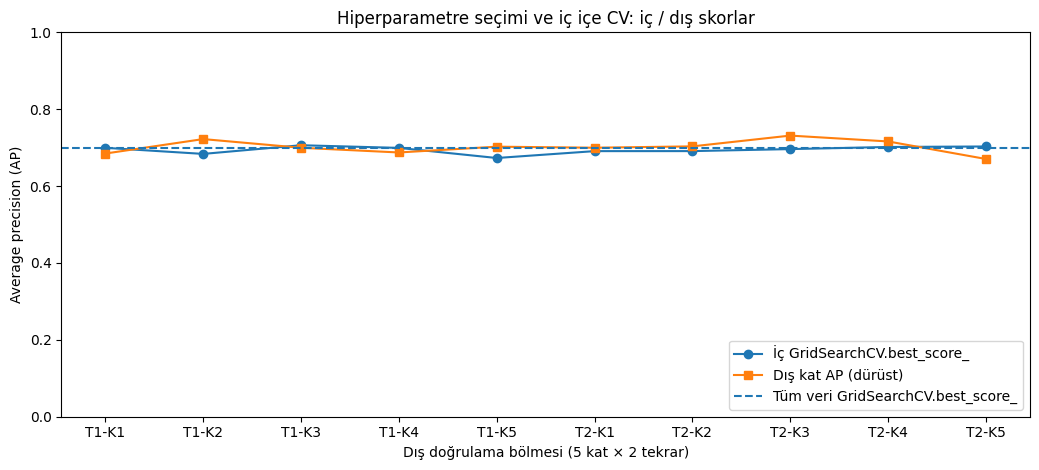

Grafik yorumu: İç seçim skoru ile bağımsız dış kat AP'si karşılaştırılmıştır.
Not: Dış kat sonuçları da aynı veri setinin tekrarlı CV ölçümleridir;
tamamen bağımsız bir nihai test kümesi değildir.


In [ ]:
# BÖLÜM 2.3 — OPTİMİST YANLILIK / GRIDSEARCH vs İÇ İÇE CV
# 2.2 ile aynı karar ağacı ailesi, aynı 6 parametre adayı.
# Tüm ön işleme yalnızca eğitim bölmesinin Pipeline'ında fit edilir.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.metrics import average_precision_score

SEED_23 = globals().get("SEED", 42)
cat_cols_23 = ["Month", "OperatingSystems", "Browser", "Region",
               "TrafficType", "VisitorType", "Weekend"]
num_cols_23 = [c for c in X.columns if c not in cat_cols_23]
# Her benzersiz girdi vektörünün bir grup kimliği vardır. Etiketler gruba dahil edilmez.
groups_23 = pd.util.hash_pandas_object(X, index=False).to_numpy()
assert len(groups_23) == len(y) == len(X)

# Bu fonksiyon her GridSearchCV/outer fold için sıfırdan yeni Pipeline oluşturur.
def tree_pipeline_23():
    preprocessing_23 = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scale", StandardScaler())
        ]), num_cols_23),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ]), cat_cols_23)
    ], sparse_threshold=0)
    return Pipeline([
        ("preprocess", preprocessing_23),
        ("model", DecisionTreeClassifier(
            class_weight="balanced", random_state=SEED_23
        ))
    ])

param_grid_23 = {
    "model__max_depth": [4, 8, 12],
    "model__min_samples_leaf": [10, 30],
}
print("Aday kombinasyonu sayısı:", 3 * 2)
print("Ölçüt: average precision (AP)")

# (A) BÜTÜN VERİDE arama: yalnızca optimist seçim skorunu göstermek için.
# Bu skoru bağımsız test başarısı ya da nihai seçilmiş modelin test başarısı saymıyoruz.
inner_all_23 = StratifiedGroupKFold(
    n_splits=3, shuffle=True, random_state=SEED_23 + 500
)
full_search_23 = GridSearchCV(
    estimator=tree_pipeline_23(), param_grid=param_grid_23,
    scoring="average_precision", cv=inner_all_23,
    refit=True, n_jobs=1, error_score="raise"
)
full_search_23.fit(X, y, groups=groups_23)
print("\n=== TÜM VERİDE GRIDSEARCH (yalnızca kıyas için) ===")
print("GridSearchCV.best_params_:", full_search_23.best_params_)
print("GridSearchCV.best_score_:", round(float(full_search_23.best_score_), 4))

# (B) GERÇEK İÇ İÇE CV: model seçimi yalnızca dış eğitim katında yapılır.
records_23 = []
for rep_23 in range(2):
    outer_cv_23 = StratifiedGroupKFold(
        n_splits=5, shuffle=True, random_state=SEED_23 + rep_23
    )
    for fold_23, (train_23, valid_23) in enumerate(
        outer_cv_23.split(X, y, groups=groups_23), start=1
    ):
        grp_train_23 = groups_23[train_23]
        assert not set(grp_train_23).intersection(groups_23[valid_23]),             "Grup sızıntısı: aynı girdi iki tarafta!"
        # Her dış eğitim katında yeniden seçilmiş hiperparametreler
        inner_cv_23 = StratifiedGroupKFold(
            n_splits=3, shuffle=True,
            random_state=SEED_23 + 100 + (rep_23 * 10) + fold_23
        )
        search_23 = GridSearchCV(
            estimator=tree_pipeline_23(), param_grid=param_grid_23,
            scoring="average_precision", cv=inner_cv_23,
            refit=True, n_jobs=1, error_score="raise"
        )
        search_23.fit(X.iloc[train_23], y.iloc[train_23],
                      groups=grp_train_23)
        probabilities_23 = search_23.best_estimator_.predict_proba(
            X.iloc[valid_23]
        )[:, 1]
        outer_score_23 = average_precision_score(
            y.iloc[valid_23], probabilities_23
        )
        records_23.append({
            "Dış kat": f"T{rep_23 + 1}-K{fold_23}",
            "İç best_score": float(search_23.best_score_),
            "Dış AP": float(outer_score_23),
            "İç - dış": float(search_23.best_score_ - outer_score_23),
            "max_depth": search_23.best_params_["model__max_depth"],
            "min_samples_leaf": search_23.best_params_["model__min_samples_leaf"],
        })
        print(f"T{rep_23 + 1}-K{fold_23}: iç {search_23.best_score_:.4f} / "
              f"dış {outer_score_23:.4f}")

nested_results_23 = pd.DataFrame(records_23)
print("\n=== İÇ İÇE CV: 5 KAT × 2 TEKRAR ===")
display(nested_results_23.round(4))

summary_23 = pd.DataFrame([
    {
        "Karşılaştırma": "Tüm veride GridSearchCV.best_score_",
        "AP ortalama": float(full_search_23.best_score_),
        "AP std": np.nan,
    },
    {
        "Karşılaştırma": "İç kat best_score_ (10 dış bölme)",
        "AP ortalama": float(nested_results_23["İç best_score"].mean()),
        "AP std": float(nested_results_23["İç best_score"].std(ddof=1)),
    },
    {
        "Karşılaştırma": "İç içe CV dış skorları (10 dış bölme)",
        "AP ortalama": float(nested_results_23["Dış AP"].mean()),
        "AP std": float(nested_results_23["Dış AP"].std(ddof=1)),
    },
])
print("\n=== GENEL KARŞILAŞTIRMA (AP: ortalama ± standart sapma) ===")
display(summary_23.round(4))
print("İç eksi dış ortalama:",
      round(float(nested_results_23["İç - dış"].mean()), 4))
print("İç eksi dış std:",
      round(float(nested_results_23["İç - dış"].std(ddof=1)), 4))

fig, ax = plt.subplots(figsize=(10.5, 4.8))
idx_23 = np.arange(len(nested_results_23))
ax.plot(idx_23, nested_results_23["İç best_score"],
        marker="o", label="İç GridSearchCV.best_score_")
ax.plot(idx_23, nested_results_23["Dış AP"],
        marker="s", label="Dış kat AP (dürüst)")
ax.axhline(full_search_23.best_score_, linestyle="--",
           label="Tüm veri GridSearchCV.best_score_")
ax.set_xticks(idx_23, nested_results_23["Dış kat"])
ax.set_ylim(0, 1)
ax.set_xlabel("Dış doğrulama bölmesi (5 kat × 2 tekrar)")
ax.set_ylabel("Average precision (AP)")
ax.set_title("Hiperparametre seçimi ve iç içe CV: iç / dış skorlar")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()
print("Grafik yorumu: İç seçim skoru ile bağımsız dış kat AP'si karşılaştırılmıştır.")
print("Not: Dış kat sonuçları da aynı veri setinin tekrarlı CV ölçümleridir;")
print("tamamen bağımsız bir nihai test kümesi değildir.")


**Yorum — 2.3 Optimist yanlılık (Colab sonuçlarıyla doğrulanmıştır)**

**Amaç ve yöntem:** Aynı `DecisionTreeClassifier(class_weight="balanced")`, altı adaylı hiperparametre ızgarası ve sınıf dengesizliğine uygun `average_precision` (AP) ölçütüyle değerlendirilmiştir. `GridSearchCV.best_score_`, hiperparametre seçiminin yapıldığı katlardan gelen bir seçim skorudur; bağımsız test başarısı değildir. Dürüst değerlendirmede her dış kat için hiperparametre araması yalnızca dış eğitim bölmesindeki üç iç kat üzerinden yeniden yapılmıştır.

**Gerçek deney sonuçları:**

- Tüm veride `GridSearchCV.best_score_`: **0,6988**; tek seçim skoru olduğu için standart sapma bu satırda raporlanmaz.
- İç katlarda seçilmiş modelin `best_score_` ortalaması (10 dış bölme): **0,6945 ± 0,0101**.
- Dış katlarda iç içe çapraz doğrulama AP'si (5 kat × 2 tekrar): **0,7018 ± 0,0182**.
- Eşleşen dış bölmelerin **iç − dış** farkı: **−0,0073 ± 0,0235**. Bu deneyde iç skorun sistematik olarak daha yüksek olduğu gözlenmedi. Bu, iyimser seçim etkisinin prensipte bulunmadığının kanıtı değildir; kat örneklemesi, veri yapısı ve skorların örnekleme değişkenliği sonuçları etkiler. Negatif fark geçerli bir bulgudur, saklanmaz.
- **Parametre kararlılığı:** 10 dış bölmenin **tamamında** `max_depth=8` ve `min_samples_leaf=30` seçildi. Bu, yalnızca *denenen altı aday* içinde kararlı seçim olduğunu gösterir; evrensel en iyi ayarlar olduğu anlamına gelmez.

**Sızıntı önlemi ve sınırlılıklar:** Her iç/dış bölmede ön işleme eğitim tarafında `Pipeline` içinde öğrenildi; aynı girdilere sahip 125 tekrar grup-korumalı bölme sayesinde eğitim/doğrulama arasında ayrılmadı. Gerçek kullanıcı kimlikleri bilinmediğinden farklı oturumların aynı kişiye ait olma olasılığı dışlanamaz. İç içe CV dış katları ayrı bir nihai test veri seti değildir. Bu deney karar ağacında yöntem göstermek içindir; Bölüm 2.1'deki lider modellerin sıralamasını kendiliğinden değiştirmez.


### 2.4 İstatistiksel test — 5×2 çapraz doğrulamalı eşleştirilmiş t-testi

**Araştırma sorusu:** Önceki karşılaştırmada ana ölçüt olan **average precision (AP)** bakımından Gradient Boosting ile Random Forest arasındaki fark, aynı doğrulama bölmelerinde nasıl değişiyor?

**Yöntem:** Dietterich (1998) tarafından ele alınan **5×2 çapraz doğrulamalı eşleştirilmiş t-testi** uygulanacaktır. Beş farklı tohumla iki katlı, grup-korumalı bölme yapılır. Her tekrardaki iki katın eğitim ve doğrulama rolleri ters çevrilir. Her katın aynı test kayıtlarında iki modelin AP skoru ölçülür; fark `Gradient Boosting − Random Forest` olarak alınır. Ön işleme bütün modeller için yalnızca o katın eğitim verisinde öğrenilir.

Test istatistiği: `t = d₁₁ / sqrt((1/5) * sum(sᵢ²))` ve `sᵢ² = (dᵢ₁ − d̄ᵢ)² + (dᵢ₂ − d̄ᵢ)²` (yaklaşık 5 serbestlik derecesi). İki yönlü p-değeri verilir. Farkların 10 ölçüm üzerinden ortalaması ve standart sapması da şeffaf biçimde raporlanır, fakat bunlar **bağımsız 10 gözlem sayılarak yapılan sıradan t-testi değildir**.

**Önemli sınırlılık:** Modeller Bölüm 2.1'de **aynı veri kümesi** sonuçları görülerek seçildiği için burada hesaplanan p-değeri **keşifsel/nominal** kabul edilir; tamamen bağımsız bir doğrulayıcı hipotez testi veya nihai test değildir. Aynı girdilerin yinelenen 125 satırı gruplarla korunur; gerçek kullanıcı kimlikleri yoktur. İstatistiksel olarak anlamlı fark çıkmaması da bilimsel açıdan geçerli bir sonuçtur.


T1-K1: GB=0.7481, RF=0.7352, fark=+0.0129
T1-K2: GB=0.7479, RF=0.7196, fark=+0.0283
T2-K1: GB=0.7471, RF=0.7314, fark=+0.0157
T2-K2: GB=0.7431, RF=0.7304, fark=+0.0127
T3-K1: GB=0.7436, RF=0.7401, fark=+0.0036
T3-K2: GB=0.7510, RF=0.7284, fark=+0.0227
T4-K1: GB=0.7392, RF=0.7139, fark=+0.0253
T4-K2: GB=0.7496, RF=0.7367, fark=+0.0129
T5-K1: GB=0.7520, RF=0.7301, fark=+0.0218
T5-K2: GB=0.7469, RF=0.7327, fark=+0.0142

=== 2.4 EŞLEŞMİŞ SKORLAR (5 × 2 = 10 doğrulama) ===


,Tekrar,Kat,GB AP,RF AP,Fark (GB-RF),Test örneği,Test satın alma oranı
0,1,1,0.7481,0.7352,0.0129,6174,0.1557
1,1,2,0.7479,0.7196,0.0283,6156,0.1538
2,2,1,0.7471,0.7314,0.0157,6179,0.1573
3,2,2,0.7431,0.7304,0.0127,6151,0.1522
4,3,1,0.7436,0.7401,0.0036,6165,0.1607
5,3,2,0.7510,0.7284,0.0227,6165,0.1487
6,4,1,0.7392,0.7139,0.0253,6180,0.1494
7,4,2,0.7496,0.7367,0.0129,6150,0.1602
8,5,1,0.7520,0.7301,0.0218,6151,0.1613
9,5,2,0.7469,0.7327,0.0142,6179,0.1482



=== 2.4 ÖZET (AP: ortalama ± std) ===


,Ölçüt,Ortalama,Std
0,Gradient Boosting AP,0.7468,0.0039
1,Random Forest AP,0.7298,0.0078
2,AP farkı (GB − RF),0.0170,0.0074


Dietterich 5×2 CV t istatistiği: 1.4244
Serbestlik derecesi: 5
İki yönlü nominal p değeri: 0.213645
Nominal p<0.05 mi? False
NOT: Modeller daha önce aynı veride seçildi; test keşifsel niteliktedir.


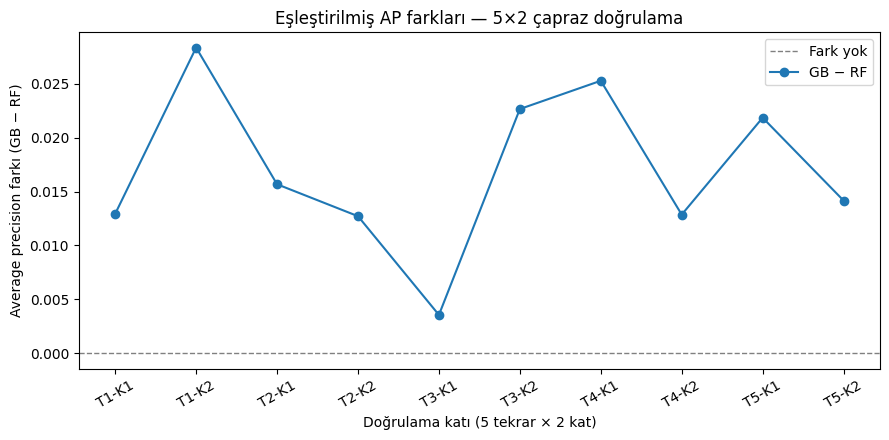

Grafik yorumu: Pozitif değerler GB, negatif değerler RF lehinedir.
Sınırlılık: Bu bölmeler bağımsız bir nihai test seti değildir.


In [ ]:
# BÖLÜM 2.4 — GRADIENT BOOSTING ve RANDOM FOREST için 5×2 CV t-testi
# Her modelde bütün ön işleme kendi eğitim katında yapılır.
# Önceki bölümlerin değişkenleri X, y, df ve sonuçları değiştirilmez.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t as student_t
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import average_precision_score
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier

SEED_24 = globals().get("SEED", 42)
cat_cols_24 = ["Month", "OperatingSystems", "Browser", "Region",
               "TrafficType", "VisitorType", "Weekend"]
num_cols_24 = [col for col in X.columns if col not in cat_cols_24]
groups_24 = pd.util.hash_pandas_object(X, index=False).to_numpy()
assert len(X) == len(y) == len(groups_24)

def make_prep_24():
    return ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scale", StandardScaler())
        ]), num_cols_24),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ]), cat_cols_24)
    ], sparse_threshold=0)

def make_model_24(which):
    if which == "Gradient Boosting":
        estimator = HistGradientBoostingClassifier(
            max_iter=100, learning_rate=0.07, max_leaf_nodes=15,
            l2_regularization=0.2, random_state=SEED_24
        )
    elif which == "Rastgele orman":
        estimator = RandomForestClassifier(
            n_estimators=150, min_samples_leaf=3,
            class_weight="balanced_subsample", random_state=SEED_24, n_jobs=1
        )
    else:
        raise ValueError("Bilinmeyen model")
    return Pipeline([("prep", make_prep_24()), ("model", estimator)])

rows_24 = []
# 5 tekrar × 2 birbirini tamamlayan kat: aynı tekrar içinde eğitim/test yer değiştirir.
for rep_24 in range(5):
    cv_24 = StratifiedGroupKFold(
        n_splits=2, shuffle=True, random_state=SEED_24 + 1000 + rep_24
    )
    pair_diffs_24 = []
    for fold_24, (train_24, test_24) in enumerate(
        cv_24.split(X, y, groups=groups_24), start=1
    ):
        assert not set(groups_24[train_24]).intersection(set(groups_24[test_24]))
        scores_24 = {}
        for model_name_24 in ["Gradient Boosting", "Rastgele orman"]:
            mdl_24 = make_model_24(model_name_24)
            mdl_24.fit(X.iloc[train_24], y.iloc[train_24])
            prob_24 = mdl_24.predict_proba(X.iloc[test_24])[:, 1]
            scores_24[model_name_24] = average_precision_score(y.iloc[test_24], prob_24)
        diff_24 = scores_24["Gradient Boosting"] - scores_24["Rastgele orman"]
        pair_diffs_24.append(float(diff_24))
        rows_24.append({
            "Tekrar": rep_24 + 1, "Kat": fold_24,
            "GB AP": scores_24["Gradient Boosting"],
            "RF AP": scores_24["Rastgele orman"],
            "Fark (GB-RF)": diff_24,
            "Test örneği": len(test_24),
            "Test satın alma oranı": float(np.asarray(y.iloc[test_24]).mean())
        })
        print(f"T{rep_24+1}-K{fold_24}: GB={scores_24['Gradient Boosting']:.4f}, "
              f"RF={scores_24['Rastgele orman']:.4f}, fark={diff_24:+.4f}")

results_24 = pd.DataFrame(rows_24)
print("\n=== 2.4 EŞLEŞMİŞ SKORLAR (5 × 2 = 10 doğrulama) ===")
display(results_24.round(4))

pairs_24 = results_24["Fark (GB-RF)"].to_numpy().reshape(5, 2)
means_24 = pairs_24.mean(axis=1, keepdims=True)
variance_24 = ((pairs_24 - means_24) ** 2).sum(axis=1)
denominator_24 = np.sqrt(variance_24.mean())
if np.isclose(denominator_24, 0):
    t_stat_24, p_value_24 = np.nan, np.nan
    print("UYARI: Varyans sıfıra yakın; test istatistiği güvenilir hesaplanamadı.")
else:
    t_stat_24 = float(pairs_24[0, 0] / denominator_24)
    p_value_24 = float(2 * student_t.sf(abs(t_stat_24), df=5))

summary_24 = pd.DataFrame([
    {"Ölçüt": "Gradient Boosting AP", "Ortalama": results_24["GB AP"].mean(),
     "Std": results_24["GB AP"].std(ddof=1)},
    {"Ölçüt": "Random Forest AP", "Ortalama": results_24["RF AP"].mean(),
     "Std": results_24["RF AP"].std(ddof=1)},
    {"Ölçüt": "AP farkı (GB − RF)", "Ortalama": results_24["Fark (GB-RF)"].mean(),
     "Std": results_24["Fark (GB-RF)"].std(ddof=1)}
])
print("\n=== 2.4 ÖZET (AP: ortalama ± std) ===")
display(summary_24.round(4))
print("Dietterich 5×2 CV t istatistiği:", round(t_stat_24, 4))
print("Serbestlik derecesi: 5")
print("İki yönlü nominal p değeri:", round(p_value_24, 6))
if np.isfinite(p_value_24):
    print("Nominal p<0.05 mi?", p_value_24 < .05)
print("NOT: Modeller daha önce aynı veride seçildi; test keşifsel niteliktedir.")

fig, ax = plt.subplots(figsize=(9, 4.5))
x_axis_24 = np.arange(len(results_24))
ax.axhline(0, color="gray", linestyle="--", linewidth=1,
           label="Fark yok")
ax.plot(x_axis_24, results_24["Fark (GB-RF)"], marker="o", linestyle="-",
        label="GB − RF")
ax.set_xticks(x_axis_24, [f"T{r}-K{k}" for r, k in
                            zip(results_24["Tekrar"], results_24["Kat"])], rotation=30)
ax.set_xlabel("Doğrulama katı (5 tekrar × 2 kat)")
ax.set_ylabel("Average precision farkı (GB − RF)")
ax.set_title("Eşleştirilmiş AP farkları — 5×2 çapraz doğrulama")
ax.legend()
fig.tight_layout()
plt.show()
print("Grafik yorumu: Pozitif değerler GB, negatif değerler RF lehinedir.")
print("Sınırlılık: Bu bölmeler bağımsız bir nihai test seti değildir.")


**Yorum — 2.4 İstatistiksel test (Colab'da çalıştırılıp doğrulanmıştır)**

**Karşılaştırılan adaylar:** Bölüm 2.1'de *average precision* (AP) sıralamasına göre öne çıkan Gradient Boosting (GB) ve Random Forest (RF) değerlendirilmiştir. Her iki model 5 tekrar × 2 kat = 10 doğrulama katında **aynı eğitim ve test kayıtları** üzerinde değerlendirilmiş; tüm ön işleme yalnızca eğitim katında öğrenilmiştir. Tam yinelenen girdiler grup-korumalı ayrılmıştır.

| Ölçüt | Sonuç (10 doğrulama) |
|---|---:|
| Gradient Boosting AP | **0,7468 ± 0,0039** |
| Random Forest AP | **0,7298 ± 0,0078** |
| Eşleştirilmiş fark (GB − RF) | **+0,0170 ± 0,0074** |
| GB'nin daha yüksek olduğu katlar | **10 / 10** |
| Dietterich 5×2 CV t-istatistiği | **t(5) = 1,4244** |
| İki yönlü nominal p-değeri | **0,213645** |

**İstatistiksel yorum:** Her 10 doğrulama parçasında GB'nin AP skoru daha yüksektir; gözlenen ortalama fark pozitif ve küçük-orta büyüklüktedir. Ancak 5×2 CV t-testinde **p = 0,213645 > 0,05** olduğundan, bu tasarımda **istatistiksel anlamlı farklılık için yeterli kanıt elde edilememiştir**. Bu, iki modelin eşit olduğunu ispatlamaz. Testin 10 skorunu bağımsız gözlem kabul eden sıradan t-testi kullanılmamıştır.

**Önemli sınırlılık:** Modeller Bölüm 2.1'de aynı veri seti üzerindeki performanslarına göre seçildiğinden bu p-değeri **keşifsel/nominal** olarak yorumlanmalıdır; bağımsız doğrulayıcı bir hipotez testi değildir. Kullanıcı kimlikleri bulunmadığından aynı kişiye ait farklı oturumlar iki kata da düşmüş olabilir. Elde edilen skorlar bağımsız nihai test kümesi başarısı değildir.

**Proje 2'ye geçici model kararı:** Amaç azınlık sınıfındaki satın alma davranışını olasılıksal skorlarla sıralamak olduğu için birincil ölçüt AP olarak tutulmuş ve **Gradient Boosting** Proje 2'ye aktarılacak *geçici aday* olarak seçilmiştir. Bölüm 2.1'de RF'nin F1 ve balanced accuracy ölçütlerinde daha iyi olduğu hatırlanmalı; proje hedefi sabit sınıf etiketi üretmekse RF de güçlü alternatiftir. Mevcut sonuçlar hiçbir modelin gerçek zamanlı kullanıma hazır veya istatistiksel olarak üstün olduğunu göstermez.


### 2.5 Proje 2'ye aktarılacak model, protokol ve çıktıların kilitlenmesi

**Gerekçeli geçici seçim:** Başlıca başarı ölçütü **average precision** olduğundan 2.1'de en yüksek ortalama skoru veren **Gradient Boosting** Proje 2 için başlangıç adayıdır (0,7571 ± 0,0161). Alternatif Random Forest'tır (0,7339 ± 0,0206; balanced accuracy ve F1'de daha güçlü). 2.4'te nominal p=0,213645 ile istatistiksel üstünlük saptanmamıştır.

**Aktarımın içeriği:** Özgün verinin temizlenmiş, şeması korunmuş kopyası; seçili model ve onun **eğitim sırasında öğrenilmiş** ön işleme hattı (`Pipeline`); özellik/ölçüt/bölme/provenans özetini taşıyan JSON; SHA-256 manifesti. Bunlar aşağıdaki hücre ile **yalnızca hücre çalıştırıldığında** üretilecektir.

**Tekrarlanabilirlik:** UCI veri kümesi 468, **12.330 oturum**, 17 girdi ve hedef Revenue. Kategorik sütunlar açıkça tanımlanır. Tohum **42** ve model parametreleri 2.1'deki Gradient Boosting ile aynıdır. Veri, model, JSON ve manifest dosyaları `p1_export/` klasörüne kaydedilir; ZIP aktarım dosyası oluşturulur. SHA-256 dosyaların değiştirilip değiştirilmediğini denetler, tek başına metodolojik doğruluğu ya da UCI sürümünü garanti etmez.

**Değerlendirme protokolü:** 2.1'deki **5 kat × 2 tekrar**, grup-korumalı `StratifiedGroupKFold` (tamamen aynı girdi kayıtları aynı grupta); bütün ön işleme eğitim katında; ana ölçüt AP; ikincil ölçütler balanced accuracy, F1 ve accuracy. 2.4'te ayrıca grup-korumalı 5×2 eşleştirilmiş t-testi kullanılmıştır. Bu protokol Proje 2'de temel alınacaktır.

> **Önemli:** Aşağıdaki kod modeli tüm veri üzerinde yeniden eğiterek **aktarım için nihai dosyaya** kaydeder. Bu eğitimden sonra aynı satırlarda alınacak skor, bağımsız test başarısı olarak yorumlanamaz. Gerçek kullanıcı kimlikleri yoktur; `PageValues` gibi oturum sonunda ortaya çıkabilen özellikler erken tahminde kullanılırsa ayrıca sızıntı/zamanlama incelemesi gerekir. Ham veri GitHub'a otomatik olarak yüklenmez.


In [ ]:
# BÖLÜM 2.5 — PROJE 2 AKTARIM DOSYALARI (model + protokol + SHA-256)
# Çalıştırıldığında kaydeder; mevcut X, y, df ve önceki CV skorlarına dokunmaz.
import hashlib
import json
import platform
import sys
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED_25 = 42
export_dir_25 = Path("p1_export")
export_dir_25.mkdir(parents=True, exist_ok=True)

# Özgün 17 girdi özelliği + hedef; sentetik eksiklik deneyindeki kopya kullanılmaz.
assert len(X) == len(y) == 12330
assert X.shape[1] == 17
assert "Revenue" not in X.columns
assert y.notna().all() and int(y.astype(int).sum()) == 1908

categorical_cols_25 = [
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend"
]
numeric_cols_25 = [c for c in X.columns if c not in categorical_cols_25]
assert len(categorical_cols_25) + len(numeric_cols_25) == X.shape[1]

# Yalnızca aktarım için bütün X üzerinde eğitilen pipeline;
# değerlendirme sonuçları daha önce eğitim/dış doğrulama ayrımıyla elde edildi.
preprocessing_25 = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), numeric_cols_25),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ]), categorical_cols_25)
], sparse_threshold=0)

model_25 = HistGradientBoostingClassifier(
    max_iter=100, learning_rate=0.07,
    max_leaf_nodes=15, l2_regularization=0.2,
    random_state=SEED_25
)
transfer_pipeline_25 = Pipeline([
    ("prep", preprocessing_25),
    ("model", model_25)
])
transfer_pipeline_25.fit(X, y)

# Kaydedilen verinin satırları / sütunları orijinal yapıdadır; 125 tekrar sessizce silinmez.
clean_data_25 = X.copy(deep=True)
clean_data_25["Revenue"] = y.to_numpy()
data_path_25 = export_dir_25 / "p1_temiz_veri.csv"
clean_data_25.to_csv(data_path_25, index=False)

pipeline_path_25 = export_dir_25 / "p1_hat.joblib"
joblib.dump(transfer_pipeline_25, pipeline_path_25)

protocol_25 = {
    "project": "BIL545 Proje 1",
    "source": "https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset",
    "uci_id": 468,
    "license": "CC BY 4.0",
    "observation_unit": "e-ticaret oturumu",
    "rows": len(X),
    "input_features": list(X.columns),
    "target": "Revenue",
    "target_positive": True,
    "positive_rows": int(y.astype(int).sum()),
    "duplicate_input_rows": int(X.duplicated().sum()),
    "missing_input_cells": int(X.isna().sum().sum()),
    "seed": SEED_25,
    "selected_model": "HistGradientBoostingClassifier",
    "model_parameters": {
        "max_iter": 100, "learning_rate": 0.07,
        "max_leaf_nodes": 15, "l2_regularization": 0.2,
        "random_state": SEED_25
    },
    "categorical_columns": categorical_cols_25,
    "numeric_columns": numeric_cols_25,
    "preprocessing": "median imputation + standard scaling (numeric); most_frequent imputation + one-hot (categorical); fit inside Pipeline",
    "selection_metric": "average_precision",
    "model_comparison_protocol": "5-fold x 2 repeats, StratifiedGroupKFold; duplicate input rows kept within same group; same splits for all models",
    "comparison_results": {
        "gradient_boosting_ap_cv_mean": 0.7571,
        "gradient_boosting_ap_cv_std": 0.0161,
        "random_forest_ap_cv_mean": 0.7339,
        "random_forest_ap_cv_std": 0.0206,
        "exploratory_5x2_t": 1.4244,
        "exploratory_5x2_p_two_sided": 0.213645
    },
    "limitations": [
        "No independent held-out test performance has been established.",
        "Model fitted on full dataset only for reuse; do not evaluate on the same data as unseen test.",
        "Duplicates grouped by identical feature vector, not by genuine user ID.",
        "PageValues and other session-derived features may not be available for early prediction.",
        "Model superiority versus Random Forest is not statistically established (exploratory nominal p=0.213645)."
    ],
    "environment": {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__,
        "joblib": joblib.__version__
    },
    "export_utc": datetime.now(timezone.utc).isoformat()
}
protocol_path_25 = export_dir_25 / "p1_protokol.json"
protocol_path_25.write_text(json.dumps(protocol_25, ensure_ascii=False, indent=2), encoding="utf-8")

# SHA-256 bütünlük manifesti; manifestin kendi özeti ve ZIP özeti ayrı raporlanır.
def sha256_25(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

payload_paths_25 = [data_path_25, pipeline_path_25, protocol_path_25]
manifest_25 = {
    "algorithm": "SHA-256",
    "files": {p.name: {"sha256": sha256_25(p), "bytes": p.stat().st_size}
              for p in payload_paths_25}
}
manifest_path_25 = export_dir_25 / "p1_manifest_sha256.json"
manifest_path_25.write_text(json.dumps(manifest_25, ensure_ascii=False, indent=2), encoding="utf-8")

# Kayıttan tekrar yüklenebildiğini ve üretim hattının tahmin ürettiğini denetle.
reloaded_25 = joblib.load(pipeline_path_25)  # yalnızca burada kendimiz ürettiğimiz güvenilir dosya
sample_probs_25 = reloaded_25.predict_proba(X.iloc[:5])[:, 1]
assert len(sample_probs_25) == 5 and np.isfinite(sample_probs_25).all()
assert len(pd.read_csv(data_path_25)) == len(X)
assert all(sha256_25(export_dir_25 / name) == info["sha256"]
           for name, info in manifest_25["files"].items())

zip_path_25 = Path("p1_proje2_aktarim.zip")
with zipfile.ZipFile(zip_path_25, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for p in payload_paths_25 + [manifest_path_25]:
        zf.write(p, arcname=f"p1_export/{p.name}")

print("=== BÖLÜM 2.5 PROJE 2 AKTARIMI HAZIR ===")
print("Aktarım modeli:", type(reloaded_25.named_steps["model"]).__name__)
print("Veri boyutu:", clean_data_25.shape)
print("İlk 5 satır için tahmin olasılıkları:", np.round(sample_probs_25, 4))
print("Dosyalar:")
for p in payload_paths_25 + [manifest_path_25]:
    print(f" - {p} | {p.stat().st_size:,} bayt | SHA-256: {sha256_25(p)}")
print("ZIP paketi:", zip_path_25, "| SHA-256:", sha256_25(zip_path_25))
print("ÖNEMLİ: Tam veriyle eğitilmiş bu dosyanın aynı veri üzerindeki skoru test skoru değildir.")

# ZIP'i bilgisayarına indirmek için isteğe bağlı çalıştır:
# from google.colab import files
# files.download(str(zip_path_25))


=== BÖLÜM 2.5 PROJE 2 AKTARIMI HAZIR ===
Aktarım modeli: HistGradientBoostingClassifier
Veri boyutu: (12330, 18)
İlk 5 satır için tahmin olasılıkları: [0.0024 0.0044 0.0031 0.0036 0.0099]
Dosyalar:
 - p1_export/p1_temiz_veri.csv | 1,156,949 bayt | SHA-256: 170b9d87aa8a31e288aa8f1850ebb539cb56755a0fe16220165ad97da2aa6d3b
 - p1_export/p1_hat.joblib | 212,266 bayt | SHA-256: 5a630777b5847c2b1fbfdbfbb3201269a77c403d2f9c41a21cb3522a6cc5e142
 - p1_export/p1_protokol.json | 2,658 bayt | SHA-256: a70d48a95da23fbf3f1211d18a0feab1fcbb58317bf63d2a8238c666389576c0
 - p1_export/p1_manifest_sha256.json | 459 bayt | SHA-256: 70e3ea4cb36e5ca971ebd764c586e9fd5d9e2c2fe6985df8b2b63c0dc460666a
ZIP paketi: p1_proje2_aktarim.zip | SHA-256: 42e5df5f755ee5aa043ff29a707b4667a99b11b2a2b3048fef7b8a80967fa377
ÖNEMLİ: Tam veriyle eğitilmiş bu dosyanın aynı veri üzerindeki skoru test skoru değildir.


**Yorum — 2.5 Proje 2 aktarımı (Colab çıktılarına göre doğrulandı)**

**Model seçimi:** Bölüm 2.1'de birincil ölçüt *average precision* bakımından **Histogram-based Gradient Boosting** öne çıkmıştır (0,7571 ± 0,0161). Random Forest (0,7339 ± 0,0206) güçlü bir alternatiftir; bazı diğer ölçütlerde daha başarılıdır. 2.4'teki keşifsel 5×2 CV testinde GB'nin AP avantajı **0,0170 ± 0,0074**, t(5)=**1,4244**, nominal iki yönlü p=**0,213645** bulunmuştur. Dolayısıyla istatistiksel üstünlük kanıtlanmamıştır; GB, Proje 2 için **geçici başlangıç modeli** olarak aktarılır.

**Çalıştırılmış Colab aktarım deneyi:** `HistGradientBoostingClassifier` içeren bütün ön işleme hattı, **12.330 satır × 18 sütun** veri, protokol ve SHA-256 manifestiyle birlikte oluşturulmuştur. Kaydedilen model tekrar yüklenmiş; ilk beş girdi için satın alma olasılıkları sırasıyla **0,0024; 0,0044; 0,0031; 0,0036; 0,0099** olarak üretilmiştir. Bu olasılıklar yalnızca yükleme/çıktı biçimi kontrolüdür, model başarım ölçütü değildir.

| Colab'da oluşturulan dosya | Boyut (bayt) | SHA-256 |
|---|---:|---|
| `p1_export/p1_temiz_veri.csv` | 1.156.949 | `170b9d87aa8a31e288aa8f1850ebb539cb56755a0fe16220165ad97da2aa6d3b` |
| `p1_export/p1_hat.joblib` | 212.266 | `5a630777b5847c2b1fbfdbfbb3201269a77c403d2f9c41a21cb3522a6cc5e142` |
| `p1_export/p1_protokol.json` | 2.658 | `a70d48a95da23fbf3f1211d18a0feab1fcbb58317bf63d2a8238c666389576c0` |
| `p1_export/p1_manifest_sha256.json` | 459 | `70e3ea4cb36e5ca971ebd764c586e9fd5d9e2c2fe6985df8b2b63c0dc460666a` |

**ZIP aktarım paketi:** `p1_proje2_aktarim.zip` — SHA-256: `42e5df5f755ee5aa043ff29a707b4667a99b11b2a2b3048fef7b8a80967fa377`.

**Sürüm ve güven sınırları:** Yukarıdaki dosyalar **Colab çalışma zamanında** oluşturulmuştur. Bu kayıtlar, ZIP paketinin Drive veya GitHub'a ayrıca yüklendiğini göstermez. Tam veri üzerinde eğitilen bu modelin aynı verideki tahmin başarısı bağımsız test skoru değildir. `PageValues` ve diğer oturum-sonu ölçümlerinin erken tahmin için kullanılabilirliği belirsizdir. Kullanıcı kimliği bulunmadığı için gerçek kişi bazında bağımsızlık kanıtlanamaz. `joblib` dosyası yalnızca güvenilen kaynaktan yüklenmelidir.


# Bölüm 3 · Veri küpü ve birliktelik analizi *(ağırlık 15)*
**Makale:** Wu, Chen ve Han (2010). Re-examination of interestingness measures in pattern mining. *Data Mining and Knowledge Discovery*, 21(3).

**Okuma notu (3–4 cümle):** …

### 3.1 Veri küpü: oturum, üç boyut, roll-up ve drill-down

**Olgu (fact):** Bir e-ticaret oturumu. **Ölçüler:** Oturum sayısı, satın alan oturum sayısı, satın alma oranı (satın alan / toplam oturum).

**Üç boyut:** `Month` (ay), `VisitorType` (yeni/geri dönen/diğer ziyaretçi türü), `Weekend` (hafta içi/hafta sonu).

- **Drill-down:** Ay × ziyaretçi türü × hafta sonu olmak üzere üç boyuttaki ayrıntılı hücreleri göster.
- **Roll-up:** Aynı veriyi ay × ziyaretçi türü, yalnızca ay ve genel toplam düzeylerine topla. Oranları *yeniden sayarak* hesapla; alt grup oranlarının basit aritmetik ortalamasını alma.
- **Simpson paradoksu kontrolü:** Genel hafta sonu–hafta içi satın alma oranı farkını, `VisitorType` ve `Month` katmanları içindeki farklarla karşılaştır. Bir alt grupta ters işaret bulunması tek başına katı Simpson paradoksunu kanıtlamaz. Yeterli büyüklükteki bütün karşılaştırılabilir alt gruplarda tam ters işaret varsa **katman bazlı tersine dönüş adayı** diye raporla; bu kontrol nedensellik kanıtı değildir.

**Önemli:** Ham `X`, `y`, `df` tabloları değiştirilmeyecek. Az gözlemli hücrelerin oranları düşük güvenilirlik taşıdığı için görselleştirmede `n < 30` ayrı gösterilir; bu eşik bir raporlama tercihi olup veri içinden seçilmemiştir.


=== 3.1 GENEL TOPLAM ===


,oturum,satin_alan,satin_alma_orani_pct
0,12330,1908,15.47


=== ROLL-UP: AYLARA GÖRE ===


,Month,oturum,satin_alan,satin_alma_orani_pct
0,Feb,184,3,1.63
1,Mar,1907,192,10.07
2,May,3364,365,10.85
3,June,288,29,10.07
4,Jul,432,66,15.28
5,Aug,433,76,17.55
6,Sep,448,86,19.20
7,Oct,549,115,20.95
8,Nov,2998,760,25.35
9,Dec,1727,216,12.51


=== ROLL-UP: AY × ZİYARETÇİ TÜRÜ (ilk 18 satır) ===


,Month,VisitorType,oturum,satin_alan,satin_alma_orani_pct
0,Feb,New_Visitor,1,0,0.00
1,Feb,Returning_Visitor,183,3,1.64
2,Mar,New_Visitor,232,36,15.52
3,Mar,Returning_Visitor,1675,156,9.31
4,May,New_Visitor,319,88,27.59
5,May,Returning_Visitor,3045,277,9.10
6,June,New_Visitor,30,7,23.33
7,June,Other,1,0,0.00
8,June,Returning_Visitor,257,22,8.56
9,Jul,New_Visitor,54,11,20.37


=== DRILL-DOWN: AY × ZİYARETÇİ TÜRÜ × HAFTA SONU (ilk 24 satır) ===


,Month,VisitorType,Weekend,oturum,satin_alan,satin_alma_orani_pct
0,Feb,New_Visitor,False,1,0,0.00
1,Feb,Returning_Visitor,False,155,2,1.29
2,Feb,Returning_Visitor,True,28,1,3.57
3,Mar,New_Visitor,False,141,24,17.02
4,Mar,New_Visitor,True,91,12,13.19
5,Mar,Returning_Visitor,False,1285,103,8.02
6,Mar,Returning_Visitor,True,390,53,13.59
7,May,New_Visitor,False,234,65,27.78
8,May,New_Visitor,True,85,23,27.06
9,May,Returning_Visitor,False,2415,201,8.32


Üç boyutlu dolu hücre sayısı: 44


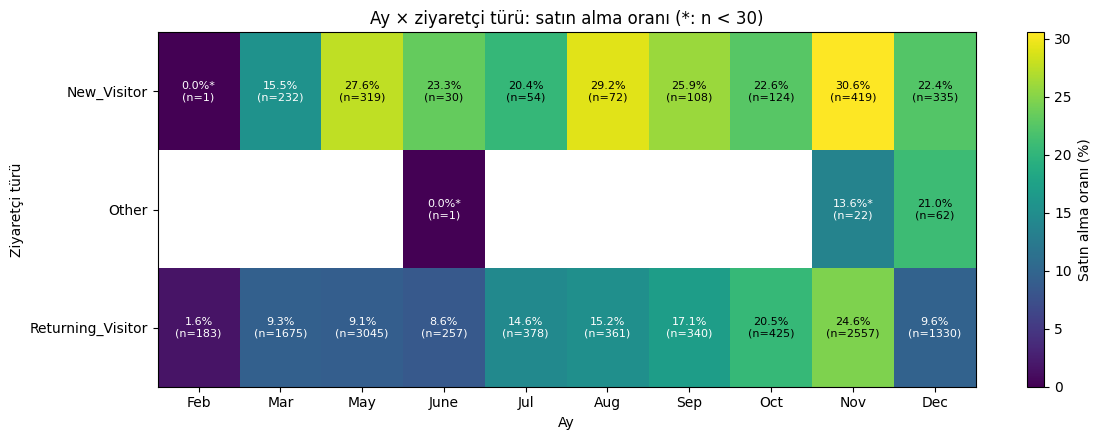

,Weekend,oturum,satin_alan,satin_alma_orani_pct
0,False,9462,1409,14.89
1,True,2868,499,17.40


Genel hafta sonu − hafta içi farkı: +0.0251 (oran puanı: +2.51)

=== VisitorType bazında Simpson kontrolü ===


,VisitorType,Hafta içi n,Hafta sonu n,Karşılaştırılabilir (her iki n ≥ 30),"Fark (hafta sonu − hafta içi, yüzde puan)"
0,New_Visitor,1215,479,True,-4.17
1,Other,78,7,False,-4.95
2,Returning_Visitor,8169,2382,True,3.31


Karşılaştırılabilir alt grup: 2
Tüm karşılaştırılabilir alt gruplarda genel eğilimin tersine dönüşü: HAYIR / KANIT YOK

=== Month bazında Simpson kontrolü ===


,Month,Hafta içi n,Hafta sonu n,Karşılaştırılabilir (her iki n ≥ 30),"Fark (hafta sonu − hafta içi, yüzde puan)"
0,Feb,156,28,False,2.29
1,Mar,1426,481,True,4.61
2,May,2649,715,True,3.80
3,June,241,47,True,0.68
4,Jul,328,104,True,0.14
5,Aug,337,96,True,-6.49
6,Sep,352,96,True,4.73
7,Oct,405,144,True,-0.15
8,Nov,2207,791,True,1.63
9,Dec,1361,366,True,-2.35


Karşılaştırılabilir alt grup: 9
Tüm karşılaştırılabilir alt gruplarda genel eğilimin tersine dönüşü: HAYIR / KANIT YOK

Yorum kuralı: Tek alt grupta işaret değişmesi katı Simpson paradoksu değildir.
Bu betimleyici karşılaştırma nedensel hafta sonu etkisi göstermez.


In [16]:
# BÖLÜM 3.1 — VERİ KÜPÜ, ROLL-UP, DRILL-DOWN ve SIMPSON KONTROLÜ
# Orijinal X, y, df DEĞİŞTİRİLMEZ.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cube_31 = X[["Month", "VisitorType", "Weekend"]].copy(deep=True)
cube_31["Revenue"] = y.to_numpy().astype(int)
assert len(cube_31) == 12330 and cube_31["Revenue"].sum() == 1908
assert cube_31.notna().sum().sum() == cube_31.size

month_order_31 = ["Jan", "Feb", "Mar", "Apr", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
cube_31["Month"] = pd.Categorical(cube_31["Month"], categories=month_order_31, ordered=True)
assert cube_31["Month"].notna().all(), "Beklenmeyen ay adı: veri sözlüğünü kontrol et"
cube_31["Weekend"] = cube_31["Weekend"].astype(bool)


def group_stats_31(dimensions):
    # Ortalama oranları ORTALAMAK yerine her grupta pay/payda üzerinden yeniden hesapla.
    if dimensions:
        grouped = (cube_31.groupby(dimensions, observed=True, dropna=False)
                   .agg(oturum=("Revenue", "size"), satin_alan=("Revenue", "sum"))
                   .reset_index())
    else:
        grouped = pd.DataFrame({"oturum": [len(cube_31)],
                                "satin_alan": [int(cube_31["Revenue"].sum())]})
    grouped["satin_alma_orani_pct"] = (100 * grouped["satin_alan"] / grouped["oturum"]).round(2)
    return grouped

# 1) Drill-down: üç boyutlu küp
cube_detail_31 = group_stats_31(["Month", "VisitorType", "Weekend"])
# 2) Roll-up: iki boyut, bir boyut, genel toplam
cube_roll_2d_31 = group_stats_31(["Month", "VisitorType"])
cube_roll_1d_31 = group_stats_31(["Month"])
cube_total_31 = group_stats_31([])

print("=== 3.1 GENEL TOPLAM ===")
display(cube_total_31)
print("=== ROLL-UP: AYLARA GÖRE ===")
display(cube_roll_1d_31)
print("=== ROLL-UP: AY × ZİYARETÇİ TÜRÜ (ilk 18 satır) ===")
display(cube_roll_2d_31.head(18))
print("=== DRILL-DOWN: AY × ZİYARETÇİ TÜRÜ × HAFTA SONU (ilk 24 satır) ===")
display(cube_detail_31.head(24))
print("Üç boyutlu dolu hücre sayısı:", len(cube_detail_31))
assert cube_detail_31["oturum"].sum() == len(cube_31)
assert cube_roll_2d_31["satin_alan"].sum() == int(cube_31["Revenue"].sum())
assert cube_roll_1d_31["oturum"].sum() == len(cube_31)

# Satın alma oranlarını ziyaretçi türü x ay düzeyinde, destek sayılarıyla göster.
heat_31 = cube_roll_2d_31.pivot(index="VisitorType", columns="Month", values="satin_alma_orani_pct")
count_31 = cube_roll_2d_31.pivot(index="VisitorType", columns="Month", values="oturum")
heat_31 = heat_31.loc[:, [c for c in month_order_31 if c in heat_31.columns]]
count_31 = count_31.reindex(index=heat_31.index, columns=heat_31.columns)
fig, ax = plt.subplots(figsize=(12, 4.5))
arr_31 = heat_31.to_numpy(dtype=float)
image_31 = ax.imshow(np.ma.masked_invalid(arr_31), aspect="auto", cmap="viridis")
ax.set_xticks(range(len(heat_31.columns)), heat_31.columns)
ax.set_yticks(range(len(heat_31.index)), heat_31.index)
for i in range(len(heat_31.index)):
    for j in range(len(heat_31.columns)):
        if pd.notna(heat_31.iat[i,j]):
            n_here = int(count_31.iat[i,j])
            # Az gözlemli hücrelerde oranı yorumlamama uyarısı: * simgesi.
            suffix = "*" if n_here < 30 else ""
            ax.text(j, i, f"{heat_31.iat[i,j]:.1f}%{suffix}\n(n={n_here})",
                    ha="center", va="center", fontsize=8, color="white" if arr_31[i,j] < 20 else "black")
fig.colorbar(image_31, ax=ax, label="Satın alma oranı (%)")
ax.set_title("Ay × ziyaretçi türü: satın alma oranı (*: n < 30)")
ax.set_xlabel("Ay")
ax.set_ylabel("Ziyaretçi türü")
fig.tight_layout()
plt.show()

# Simpson kontrolünde incelenen etki: hafta sonu – hafta içi satın alma oranı.
weekend_31 = group_stats_31(["Weekend"])
display(weekend_31)
base_weekend_31 = (cube_31.groupby("Weekend", observed=True)["Revenue"].mean().reindex([False, True]))
overall_diff_31 = float(base_weekend_31[True] - base_weekend_31[False])
print(f"Genel hafta sonu − hafta içi farkı: {overall_diff_31:+.4f} (oran puanı: {overall_diff_31*100:+.2f})")


def simpson_check_31(dimension, min_group_n=30):
    g = (cube_31.groupby([dimension, "Weekend"], observed=True)
         .agg(n=("Revenue", "size"), count=("Revenue", "sum"))
         .reset_index())
    n_wide = g.pivot(index=dimension, columns="Weekend", values="n").reindex(columns=[False,True])
    buy_wide = g.pivot(index=dimension, columns="Weekend", values="count").reindex(columns=[False,True])
    valid = n_wide.notna().all(axis=1) & (n_wide >= min_group_n).all(axis=1)
    result = pd.DataFrame({
        dimension: n_wide.index.astype(str),
        "Hafta içi n": n_wide[False].to_numpy(),
        "Hafta sonu n": n_wide[True].to_numpy(),
        "Karşılaştırılabilir (her iki n ≥ 30)": valid.to_numpy(),
        "Fark (hafta sonu − hafta içi, yüzde puan)":
            (100 * (buy_wide[True] / n_wide[True] - buy_wide[False] / n_wide[False])).to_numpy()
    })
    valid_diff = result.loc[result["Karşılaştırılabilir (her iki n ≥ 30)"],
                            "Fark (hafta sonu − hafta içi, yüzde puan)"].dropna()
    reversed_all = (len(valid_diff) >= 2 and overall_diff_31 != 0 and
                    (valid_diff * overall_diff_31 < 0).all())
    print(f"\n=== {dimension} bazında Simpson kontrolü ===")
    display(result.round(2))
    print("Karşılaştırılabilir alt grup:", len(valid_diff))
    print("Tüm karşılaştırılabilir alt gruplarda genel eğilimin tersine dönüşü:",
          "EVET — incelemeye değer aday" if reversed_all else "HAYIR / KANIT YOK")
    return result, reversed_all

simpson_visitor_31, reversal_visitor_31 = simpson_check_31("VisitorType")
simpson_month_31, reversal_month_31 = simpson_check_31("Month")
print("\nYorum kuralı: Tek alt grupta işaret değişmesi katı Simpson paradoksu değildir.")
print("Bu betimleyici karşılaştırma nedensel hafta sonu etkisi göstermez.")


**Yorum — 3.1 Veri küpü (Colab çıktılarıyla doğrulanmıştır)**

**Küp tasarımı ve toplulaştırma:** Bir satır bir *e-ticaret oturumudur* (olgu). Boyutlar `Month`, `VisitorType`, `Weekend`; ölçüler `oturum`, `satin_alan` ve yeniden hesaplanan `satin_alma_orani_pct`. Üç boyutlu küpte **44 dolu hücre** gözlenmiştir. Genel toplamda **12.330 oturum / 1.908 satın alma / %15,47 satın alma oranı** elde edilmiştir. Roll-up (genel ve ay toplamları) ile drill-down (ay × ziyaretçi türü × hafta sonu) aynı toplamların farklı ayrıntı düzeyleridir; oranlar alt grup yüzdelerinin aritmetik ortalamasından değil toplam sayılardan hesaplanmıştır.

**Aylık bulgular:** En yüksek satın alma oranı **Kasım %25,35 (760 / 2.998)**, en düşük oran **Şubat %1,63 (3 / 184)**. En çok oturum ise **Mayıs ayında 3.364**, o ayın satın alma oranı yalnızca **%10,85 (365/3.364)**. Demek ki yüksek trafik hacmi otomatik olarak yüksek dönüşüm oranı anlamına gelmez. Bir yıllık veri içindeki ay kategorileri mevsimselliği çağrıştırsa da farklı yıllara genellenemez ve nedensel yorum yapılamaz.

**Isı haritası ve alt gruplar:** Kasım ayında `New_Visitor` için **%30,55 (128 / 419)**, `Returning_Visitor` için yaklaşık **%24,6 (629 / 2.557)** dönüşüm vardır. Mayısta `New_Visitor` **%27,59 (88 / 319)** iken `Returning_Visitor` yaklaşık **%9,10 (277 / 3.045)** düzeyindedir. Isı haritasındaki yıldızlı hücrelerde **n < 30** olduğundan sonuçlar kararsız olabilir: örneğin Şubat `New_Visitor` **0/1**, haziran `Other` **0/1**. Bu küçük hücrelerden genellemeye gidilmemelidir.

**Hafta sonu farkı:** Hafta içi satın alma oranı **%14,89 (1.409 / 9.462)**; hafta sonu **%17,40 (499 / 2.868)**; genel fark **+2,51 yüzde puan**. Ancak `VisitorType` düzeyinde hafta sonu − hafta içi farkı `New_Visitor` için **−4,17 yüzde puan**, `Returning_Visitor` için **+3,31 yüzde puandır**. `Other` alt grubunda hafta sonu n=7 olduğundan güvenilir bir karşılaştırma yapılmamıştır. `Month` düzeyinde yeterli gözlemli dokuz ayın bazıları pozitif, bazıları negatif fark göstermektedir (ör. Ağustos **−6,49 yüzde puan**).

**Simpson paradoksu denetimi:** Genel fark pozitif olmasına rağmen bazı alt gruplarda negatif fark görülmesi **tek başına katı Simpson paradoksu değildir**. İncelenen ziyaretçi türü ve ay katmanlarının *tüm karşılaştırılabilir alt gruplarında* genel eğilime ters ortak yön bulunmamıştır. Bu analizde **Simpson paradoksuna ilişkin tutarlı tersine dönüş kanıtı bulunmamıştır**. Karıştırıcı değişkenler ve çok küçük hücreler nedeniyle "hafta sonu satın almaya neden olur" sonucu çıkarılamaz.


### 3.2 Birliktelik analizi — Seçenek A: her oturum bir işlem

**Yönergedeki seçimin gerekçesi:** Seçenek A, *sepet/sipariş/oturum/ziyaret* türünde işlem bilgisi içeren veriler içindir. UCI 468'de **her satır bir ziyaret oturumudur**; dolayısıyla bu çalışmada **Seçenek A** uygulanacaktır. Bununla birlikte veri, satın alınan ürün kimliklerini veya ayrıntılı tıklama dizisini içermez. Bu nedenle "işlemdeki öğeler", **oturumun ölçülen özelliklerinden türetilmiş betimleyici etiketlerdir** (ör. `Month=Nov`, `VisitorType=New_Visitor`, `PageValues=positive_10_50`). Bu kurallar ürünlerin birlikte satın alındığını değil, **oturum özelliklerinin birlikte görüldüğünü** ifade eder.

**Alternatif işlem tanımı:** Bir işlem bir *ürün sepeti* olsaydı her satır için ürün kimlikleri gerekir ve kurallar ürün birlikteliğini anlatırdı. Mevcut veri seti böyle bir sepet bilgisi içermediğinden bu tanım kullanılamaz. Bir işlemi tek bir ziyaretçinin *birden fazla oturumu* olarak tanımlamak da mümkün değildir, çünkü anonim kişi kimliği verilmemektedir.

**Öznitelikleri öğelere dönüştürme:** `Month`, `VisitorType`, `Weekend` ve `TrafficType` nominal olarak korunur. `PageValues`, `BounceRates`, `ExitRates`, ürün sayfası sayısı ve süre gibi sayısal değişkenler, **açıkça belirtilen önceden sabit eşiklerle** kategorilere ayrılır. Böylece her oturum, her öznitelikten birer adet `özellik=değer` öğesi içerir. `Revenue=Yes/No` öğesi sonraki kurallarda yalnızca **betimleyici çıktı** olarak kullanılabilir; bir tahmin modelinin girdisi değildir.

**Deney planı:** Bölüm 3.3'te **Apriori ile FP-Growth** aynı ikili işlem matrisi üzerinde en az üç eşik (`min_support = 0.03, 0.05, 0.10`) ile karşılaştırılacak. Kuralları güven, lift ve Kulczynski ile değerlendireceğiz; nadir öğeler ve **200 ilgisiz öğe** üzerinden null-invariance analizi yapacağız. Bölüm 3.4'te aynı ayrıklaştırılmış tablo Weka Apriori ile kontrol edilecek. Özgün `X`, `y`, `df` **değiştirilmez**.

**Sınırlılık:** Kullanılan kesme noktaları örnek analiz için seçilmiş betimleyici varsayımlardır. Farklı eşikler farklı sık öğe kümeleri ve birliktelik kuralları üretebilir. Birliktelik nedensellik veya genelleme garantisi değildir.


In [ ]:
# BÖLÜM 3.2 — HER E-TİCARET OTURUMUNU ÖĞE KÜMESİNE DÖNÜŞTÜRME
# Orijinal X, y, df ve önceki deneyler DEĞİŞTİRİLMEZ.
import pandas as pd
import numpy as np

assert len(X) == len(y) == 12330
assert "Revenue" not in X.columns

# Yalnızca bu bölümde kullanılacak kategorik işlem tablosu.
transactions_table_32 = pd.DataFrame(index=X.index)
transactions_table_32["Month"] = X["Month"].astype(str)
transactions_table_32["VisitorType"] = X["VisitorType"].astype(str)
transactions_table_32["Weekend"] = np.where(X["Weekend"].astype(bool), "Weekend", "Weekday")
transactions_table_32["TrafficType"] = "T" + X["TrafficType"].astype(int).astype(str)

# Sabit/yorumlanabilir eşikler: sıfır ile pozitif değerleri ayrı görmek önemli.
transactions_table_32["PageValues"] = pd.cut(
    X["PageValues"], bins=[-np.inf, 0, 10, 50, np.inf],
    labels=["zero", "positive_0_10", "positive_10_50", "positive_50_plus"]
).astype(str)
transactions_table_32["ProductRelated"] = pd.cut(
    X["ProductRelated"], bins=[-np.inf, 0, 10, 40, np.inf],
    labels=["zero", "one_to_10", "11_to_40", "41_plus"]
).astype(str)
transactions_table_32["ProductRelated_Duration"] = pd.cut(
    X["ProductRelated_Duration"], bins=[-np.inf, 0, 600, 1800, np.inf],
    labels=["zero", "positive_0_600", "positive_600_1800", "positive_1800_plus"]
).astype(str)
transactions_table_32["BounceRates"] = pd.cut(
    X["BounceRates"], bins=[-np.inf, 0, 0.05, np.inf],
    labels=["zero", "positive_0_005", "over_005"]
).astype(str)
transactions_table_32["ExitRates"] = pd.cut(
    X["ExitRates"], bins=[-np.inf, 0.05, 0.15, np.inf],
    labels=["low_up_to_005", "medium_005_015", "high_over_015"]
).astype(str)

# Revenue sadece açıklayıcı birliktelik öğesi; gelecekteki satın almayı öngören girdi değildir.
transactions_table_32["Revenue"] = np.where(y.astype(bool).to_numpy(), "Yes", "No")
assert not transactions_table_32.isna().any().any()
assert not (transactions_table_32 == "nan").any().any()
assert (transactions_table_32["Revenue"] == "Yes").sum() == 1908

# Her oturumda her özellik için tam olarak bir öğe bulunur.
transaction_matrix_32 = pd.get_dummies(transactions_table_32, prefix_sep="=", dtype=bool)
assert transaction_matrix_32.shape[0] == 12330
assert transaction_matrix_32.sum(axis=1).eq(transactions_table_32.shape[1]).all()
assert set(["Revenue=Yes", "Revenue=No"]).issubset(transaction_matrix_32.columns)

print("=== 3.2 İŞLEM (TRANSACTION) TANIMI ===")
print("Seçenek: A — bir oturum = bir işlem; öğeler oturumun ayrıklaştırılmış özellikleri")
print("Oturum / işlem sayısı:", len(transactions_table_32))
print("İşlem başına öğe sayısı:", transactions_table_32.shape[1])
print("Toplam farklı öğe sayısı:", transaction_matrix_32.shape[1])
print("Revenue=Yes destek oranı:", round(float(transaction_matrix_32["Revenue=Yes"].mean()), 4))
print("\nİlk 5 oturumun ayrıklaştırılmış hali:")
display(transactions_table_32.head())
print("\nEn sık görülen 15 öğe (frekans / destek):")
item_frequency_32 = pd.DataFrame({
    "Oturum sayısı": transaction_matrix_32.sum(axis=0).astype(int),
    "Destek": transaction_matrix_32.mean(axis=0).round(4)
}).sort_values("Oturum sayısı", ascending=False)
display(item_frequency_32.head(15))
print("\nHer işlemdeki öğe sayısının dağılımı:")
display(transaction_matrix_32.sum(axis=1).value_counts().sort_index().rename("Oturum sayısı").to_frame())
print("\nNot: Bu kurallar gerçek ürün sepetleri değil, oturum davranışı etiketleri hakkındadır.")
print("Bölüm 3.3'te min_support=0.03, 0.05, 0.10 eşikleri karşılaştırılacak.")


**Yorum — 3.2 Birliktelik seçimi ve işlemleştirme (Colab çıktıları beklenecek)**

**Seçim:** Yönerge, oturum bilgisini **Seçenek A** kapsamına açıkça dahil eder. Dolayısıyla işlem birimi **bir e-ticaret oturumu**, öğe ise o oturumun bir kategorik davranış etiketi olarak tanımlanmıştır. Ürün/sepet kimliği olmadığından bunlar gerçek ürün birliktelikleri değildir; oturum profillerindeki birlikte görülme örüntüleridir.

**Hazırlanan betimleyici veri:** 12.330 oturumun her biri için 10 öğe vardır (`Month`, `VisitorType`, `Weekend`, `TrafficType`, beş ayrıklaştırılmış sayısal özellik ve `Revenue`). Sayısal bantların sınırları notebook kodunda açıkça belirtilmiştir. `Revenue` hedefi, yalnızca betimleyici kuralların sonuç öğesidir; sınıflandırıcı girdisi yapılmamıştır.

**Çalıştırıldıktan sonra tamamlanacak:** Farklı öğe sayısı **[COLAB ÇIKTISI]**; en sık 5 öğe **[COLAB ÇIKTISI]**; örnek oturum **[COLAB ÇIKTISI]**. Tekil işlem sayısının 12.330, `Revenue=Yes` desteğinin yaklaşık **%15,47** olduğu kontrol edilecektir.

**Alternatiflerin etkisi:** Ürün kimliklerine göre bir sepet kuralları analizi bu veriyle yapılamaz. Ayrıklaştırma eşikleri değiştiğinde öğelerin sıklığı ve sonraki kurallar değişebilir. Bulunan birliktelikler keşifseldir, nedensel sonuç değildir. Tekrar eden 125 kayıt korunmuştur; bulguların etkilenme olasılığı sınırlılık olarak not edilir.


### 3.3 Kurallar ve ilgi ölçütleri
**A:** işlem tanımı; Apriori ve FP-Growth, en az üç `min_support`; güven, lift ve Kulczynski; null-invariance testi.
**B:** ayrıklaştırma ve "öznitelik = değer" işlemleri; hedefe yönelik kurallar; lift ve Kulczynski; Proje 1 modelinin önemli öznitelikleriyle karşılaştırma.
İki seçenekte de üç kuralın alan bilgisiyle yorumu.

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 3.4 Weka ile kontrol
Aynı eşiklerde Weka Apriori çıktısı.

In [ ]:
weka_apriori = """

"""

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

## Varsayım defteri
Bu ödevde verdiğiniz her kararı ve gerekçesini madde madde yazın (ön işleme, ölçüt, eşik, parametre, veri seçimi). En az bir kararın ödev makalesine dayandığını belirtin.

- **Karar:** … — **Gerekçe:** …
- **Karar:** … — **Gerekçe:** …

## Katkı beyanı (zorunlu)

Bu çalışma **tek kişi** tarafından yürütülmektedir. Öğrenci: **[AD SOYAD — DOLDURULACAK]**.

- **Bölüm 1 (1.1–1.7):** [Gerçekleştirilen kod, analiz ve yorumlar tamamlandıktan sonra somutlaştırılacak]
- **Bölüm 2 (2.1–2.5):** [Gerçek katkılar tamamlandıktan sonra yazılacak]
- **Bölüm 3 (3.1–3.4):** [Gerçek katkılar tamamlandıktan sonra yazılacak]
- **Sunum:** [Anlatılacak alt başlıklar ve hazırlık]

GitHub commit geçmişiyle ve yapılan çalışmalarla tutarlı biçimde güncellenecektir.


## Yapay zekâ beyanı

ChatGPT, yönergenin yorumlanması, bireysel çalışma kapsamının belirlenmesi, GitHub README dosyasının hazırlanması, öğretim üyesinin Colab şablonunun tek kişilik kullanıma uyarlanması ve UCI veri yükleme kodunun taslağı için kullanılmıştır. **Model deneyleri henüz çalıştırılmamıştır.** Sonraki yapay zekâ kullanımları ve insan tarafından yapılan doğrulamalar çalışma ilerledikçe buraya eklenecektir.


## Kaynaklar

- [UCI Online Shoppers Purchasing Intention Dataset](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset)
- Sakar & Kastro (2018). *Online Shoppers Purchasing Intention Dataset*. https://doi.org/10.24432/C5F88Q
- Kaufman vd. (2012). *Leakage in data mining: Formulation, detection, and avoidance*.
- Dietterich (1998). *Approximate statistical tests for comparing supervised classification learning algorithms*.
- Wu, Chen ve Han (2010). *Re-examination of interestingness measures in pattern mining*.
